# 1. Football Expected Goals Prediction

We estimate the probability that a non-penalty football shot becomes a goal and ask whether shot context improves prediction beyond distance and angle. We compare Logistic Regression and Support Vector Machine (SVM) models using two feature sets: distance and angle alone, and distance and angle with shot context. The predicted probability of a goal is the shot’s expected goals (xG) value.

Run the cells in order in a fresh copy of the repository. In Google Colab, upload the repository ZIP when prompted. The StatsBomb extraction needs an internet connection and can take time. A full run regenerates the data, predictions, metrics, and model files in that copy.


## Reproducibility and Environment

The final SVM execution recorded Python 3.13.18 and scikit-learn 1.6.1. These versions describe that SVM run, not necessarily every stage of the project. The code uses seed 42 when sampling available matches, creating the match-level train/test split, and creating the three-fold model validation splits.

The committed dataset contains 12,374 non-penalty shots from 500 matches. The saved split assigns 9,900 shots from 400 matches to training and 2,474 shots from 100 matches to testing. To reproduce the reported model results, use `data/processed/modeling_dataset.csv` together with `data/processed/model_split.csv`. Running a fresh StatsBomb extraction can produce a different sample and regenerate those files.

Use the same scikit-learn version when reproducing the reported SVM tuning results. `StratifiedGroupKFold` can assign different validation folds across versions even with the same seed, which can change the selected hyperparameters. The setup cell does not pin scikit-learn, so check its installed version before comparing a new run with the reported results.


## Setup

Install the libraries used by the extraction, feature engineering, and modelling stages, then locate the repository once for the whole notebook.


In [ ]:
%pip install -q pandas numpy matplotlib mplsoccer scikit-learn scipy statsbombpy tqdm joblib


In [ ]:
from pathlib import Path
import sys
import zipfile

DATA_FILE = "data/processed/modeling_dataset.csv"
project_root = Path.cwd()
if not (project_root / DATA_FILE).exists():
    if (project_root.parent / DATA_FILE).exists():
        project_root = project_root.parent
    else:
        from google.colab import files
        print("Upload the IT461 project repository ZIP:")
        uploaded = files.upload()
        zip_name = next(name for name in uploaded if name.lower().endswith(".zip"))
        with zipfile.ZipFile(zip_name) as archive:
            archive.extractall(Path.cwd())
        project_root = next(
            path for path in Path.cwd().iterdir()
            if path.is_dir() and (path / DATA_FILE).exists()
        )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
print("Project folder:", project_root)


Upload the IT461 project repository ZIP:


Saving IT461-football-shot-probability-main.zip to IT461-football-shot-probability-main.zip
Project folder: /content/IT461-football-shot-probability-main


# 2. Dataset Preparation and Extraction

We collect non-penalty shots from a reproducible sample of 500 StatsBomb Open Data matches and retain the fields used later in the project.


In [ ]:
import pandas as pd
from statsbombpy import sb
from tqdm.auto import tqdm

TARGET_MATCHES = 500
RANDOM_STATE = 42

RAW_INPUT_FIELDS = [
    "location",
    "shot_body_part",
    "shot_technique",
    "shot_first_time",
    "shot_type",
    "play_pattern",
    "under_pressure",
]

KEEP_COLUMNS = [
    "match_id",
    "id",
    "team",
    "player",
    *RAW_INPUT_FIELDS,
    "shot_outcome",
    "shot_statsbomb_xg",
]


## 2.1 Get available matches

In [ ]:
competitions = sb.competitions()

match_frames = []

competition_seasons = competitions[
    ["competition_id", "season_id"]
].drop_duplicates()

for row in tqdm(
    competition_seasons.itertuples(index=False),
    total=len(competition_seasons),
    desc="Loading match lists"
):
    try:
        matches = sb.matches(
            competition_id=int(row.competition_id),
            season_id=int(row.season_id)
        )

        match_columns = [
            c for c in
            ["match_id", "match_date", "competition", "season", "home_team", "away_team"]
            if c in matches.columns
        ]

        match_frames.append(matches[match_columns])

    except Exception as e:
        print(
            f"Skipped competition {row.competition_id}, "
            f"season {row.season_id}: {e}"
        )

all_matches = (
    pd.concat(match_frames, ignore_index=True)
      .drop_duplicates(subset="match_id")
      .reset_index(drop=True)
)

candidate_matches = (
    all_matches.sample(frac=1, random_state=RANDOM_STATE)
               .reset_index(drop=True)
)

print(f"Available open-data matches: {len(all_matches):,}")
print(f"Target sample: {min(TARGET_MATCHES, len(all_matches)):,} matches")


/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


Loading match lists:   0%|          | 0/80 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: 

Available open-data matches: 3,961
Target sample: 500 matches


## 2.2 Extract non-penalty shots

In [ ]:
shot_frames = []
successful_match_ids = []
failed_match_ids = []

for match_id in tqdm(candidate_matches["match_id"], desc="Loading events"):
    if len(successful_match_ids) >= TARGET_MATCHES:
        break

    try:
        events = sb.events(match_id=int(match_id))

        match_shots = events.loc[events["type"].eq("Shot")].copy()
        match_shots = match_shots.loc[
            ~match_shots["shot_type"].eq("Penalty")
        ].copy()

        # Keep the selected raw fields only.
        for column in KEEP_COLUMNS:
            if column not in match_shots.columns:
                match_shots[column] = pd.NA

        shot_frames.append(match_shots[KEEP_COLUMNS])
        successful_match_ids.append(int(match_id))

    except Exception as e:
        failed_match_ids.append(int(match_id))
        print(f"Skipped match {match_id}: {e}")

shots = pd.concat(shot_frames, ignore_index=True)

used_matches = all_matches[
    all_matches["match_id"].isin(successful_match_ids)
].copy()

print(f"Matches loaded: {len(successful_match_ids):,}")
print(f"Non-penalty shots: {len(shots):,}")
print(f"Saved columns: {len(shots.columns)}")
print(f"Failed matches: {len(failed_match_ids)}")

shots.head()


Loading events:   0%|          | 0/3961 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: 

Matches loaded: 500
Non-penalty shots: 12,374
Saved columns: 13
Failed matches: 0


,match_id,id,team,player,location,shot_body_part,shot_technique,shot_first_time,shot_type,play_pattern,under_pressure,shot_outcome,shot_statsbomb_xg
0,3939988,20be3941-09d4-4073-98f7-a56806520e3e,Mexico,Orbelín Pineda Alvarado,"[96.5, 57.7]",Right Foot,Normal,NaN,Open Play,Regular Play,NaN,Blocked,0.011882
1,3939988,1e67056c-794f-4f1a-98b1-12a347a1dfb6,Mexico,César Saúl Huerta Valera,"[98.2, 37.5]",Left Foot,Half Volley,True,Open Play,Regular Play,True,Off T,0.057859
2,3939988,9265e407-3347-4c35-8e52-6b3811cf48f7,Mexico,Orbelín Pineda Alvarado,"[102.0, 57.9]",Right Foot,Normal,NaN,Open Play,Regular Play,NaN,Blocked,0.016745
3,3939988,955126e9-b026-4a35-a255-d4bf81b545f7,Ecuador,Moisés Isaac Caicedo Corozo,"[94.3, 30.3]",Right Foot,Normal,NaN,Free Kick,From Free Kick,NaN,Blocked,0.053783
4,3939988,3b4bdfd2-d26f-4244-bf75-aff5a7a5ff76,Ecuador,Ray Kendry Páez Andrade,"[92.6, 34.4]",Left Foot,Half Volley,True,Open Play,From Free Kick,NaN,Saved,0.017840


## 2.3 Dataset summary

In [ ]:
goal_count = shots["shot_outcome"].eq("Goal").sum()
non_goal_count = len(shots) - goal_count
goal_rate = goal_count / len(shots) if len(shots) else 0

summary = pd.DataFrame({
    "Statistic": [
        "Matches",
        "Non-penalty shots",
        "Raw model input fields",
        "Total columns in saved shot file",
        "Target classes",
        "Goals",
        "Non-goals",
        "Goal rate",
    ],
    "Value": [
        len(successful_match_ids),
        len(shots),
        len(RAW_INPUT_FIELDS),
        len(shots.columns),
        2,
        int(goal_count),
        int(non_goal_count),
        f"{goal_rate:.2%}",
    ]
})

display(summary)


,Statistic,Value
0,Matches,500
1,Non-penalty shots,12374
2,Raw model input fields,7
3,Total columns in saved shot file,13
4,Target classes,2
5,Goals,1383
6,Non-goals,10991
7,Goal rate,11.18%


In [ ]:
feature_summary = pd.DataFrame({
    "Raw field": RAW_INPUT_FIELDS,
    "Role": [
        "Shot location coordinates",
        "Body part used for the shot",
        "Shot technique",
        "Whether the shot was first-time",
        "Shot type",
        "Play pattern leading to the shot",
        "Whether the shooter was under pressure",
    ]
})

display(feature_summary)


,Raw field,Role
0,location,Shot location coordinates
1,shot_body_part,Body part used for the shot
2,shot_technique,Shot technique
3,shot_first_time,Whether the shot was first-time
4,shot_type,Shot type
5,play_pattern,Play pattern leading to the shot
6,under_pressure,Whether the shooter was under pressure


## 2.4 Representative examples

In [ ]:
goal_examples = shots[shots["shot_outcome"].eq("Goal")].sample(
    n=min(3, goal_count),
    random_state=RANDOM_STATE
)

non_goal_examples = shots[~shots["shot_outcome"].eq("Goal")].sample(
    n=min(3, non_goal_count),
    random_state=RANDOM_STATE
)

example_rows = pd.concat(
    [goal_examples, non_goal_examples],
    ignore_index=True
)

display(
    example_rows[
        [
            "location",
            "shot_body_part",
            "shot_technique",
            "shot_first_time",
            "shot_type",
            "play_pattern",
            "under_pressure",
            "shot_outcome",
        ]
    ]
)


## 2.5 Export

In [ ]:
raw_dir = project_root / "data" / "raw"
metadata_dir = project_root / "data" / "metadata"

# Create the folders if they do not already exist.
raw_dir.mkdir(parents=True, exist_ok=True)
metadata_dir.mkdir(parents=True, exist_ok=True)

shots.to_csv(
    raw_dir / "statsbomb_non_penalty_shots_raw.csv",
    index=False
)

used_matches.to_csv(
    metadata_dir / "statsbomb_selected_matches.csv",
    index=False
)

summary.to_csv(
    metadata_dir / "statsbomb_dataset_summary.csv",
    index=False
)

print("Saved:")
print("- data/raw/statsbomb_non_penalty_shots_raw.csv")
print("- data/metadata/statsbomb_selected_matches.csv")
print("- data/metadata/statsbomb_dataset_summary.csv")

**Note:** `shot_statsbomb_xg` is retained only as a later benchmark. It must not be used as a model input. Distance, angle, encoded categories, and the binary goal target are intentionally not created in this preparation stage.

# 3. Data Cleaning

We handle missing Boolean flags, create the binary goal target, and check the data before modelling.


In [ ]:
import pandas as pd

# Load the raw dataset produced by the data-preparation stage.
raw_path = project_root / "data" / "raw" / "statsbomb_non_penalty_shots_raw.csv"
df = pd.read_csv(raw_path)

# Preserve a copy of the original dataset.
df_raw = df.copy()

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (12374, 13)


,match_id,id,team,player,location,shot_body_part,shot_technique,shot_first_time,shot_type,play_pattern,under_pressure,shot_outcome,shot_statsbomb_xg
0,3939988,20be3941-09d4-4073-98f7-a56806520e3e,Mexico,Orbelín Pineda Alvarado,"[96.5, 57.7]",Right Foot,Normal,NaN,Open Play,Regular Play,NaN,Blocked,0.011882
1,3939988,1e67056c-794f-4f1a-98b1-12a347a1dfb6,Mexico,César Saúl Huerta Valera,"[98.2, 37.5]",Left Foot,Half Volley,True,Open Play,Regular Play,True,Off T,0.057859
2,3939988,9265e407-3347-4c35-8e52-6b3811cf48f7,Mexico,Orbelín Pineda Alvarado,"[102.0, 57.9]",Right Foot,Normal,NaN,Open Play,Regular Play,NaN,Blocked,0.016745
3,3939988,955126e9-b026-4a35-a255-d4bf81b545f7,Ecuador,Moisés Isaac Caicedo Corozo,"[94.3, 30.3]",Right Foot,Normal,NaN,Free Kick,From Free Kick,NaN,Blocked,0.053783
4,3939988,3b4bdfd2-d26f-4244-bf75-aff5a7a5ff76,Ecuador,Ray Kendry Páez Andrade,"[92.6, 34.4]",Left Foot,Half Volley,True,Open Play,From Free Kick,NaN,Saved,0.017840


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12374 entries, 0 to 12373
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   match_id           12374 non-null  int64  
 1   id                 12374 non-null  object 
 2   team               12374 non-null  object 
 3   player             12374 non-null  object 
 4   location           12374 non-null  object 
 5   shot_body_part     12374 non-null  object 
 6   shot_technique     12374 non-null  object 
 7   shot_first_time    3880 non-null   object 
 8   shot_type          12374 non-null  object 
 9   play_pattern       12374 non-null  object 
 10  under_pressure     3096 non-null   object 
 11  shot_outcome       12374 non-null  object 
 12  shot_statsbomb_xg  12374 non-null  float64
dtypes: float64(1), int64(1), object(11)
memory usage: 1.2+ MB


## 3.1 Handling Missing Values

Missing values were identified in the **shot_first_time** and **under_pressure** attributes. Since these attributes represent Boolean flags, missing values are treated as False, indicating that the corresponding condition was not recorded as present. This approach preserves all shot records without removing potentially useful training data.

In [ ]:
# Check missing values in each column
print("Missing values before cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
match_id                0
id                      0
team                    0
player                  0
location                0
shot_body_part          0
shot_technique          0
shot_first_time      8494
shot_type               0
play_pattern            0
under_pressure       9278
shot_outcome            0
shot_statsbomb_xg       0
dtype: int64


In [ ]:
# Replace missing values with False
df["shot_first_time"] = df["shot_first_time"].fillna(False)
df["under_pressure"] = df["under_pressure"].fillna(False)


print("Missing values after cleaning:")
print(df.isnull().sum())

# Check the data types
print(df[["shot_first_time", "under_pressure"]].dtypes)


Missing values after cleaning:
match_id             0
id                   0
team                 0
player               0
location             0
shot_body_part       0
shot_technique       0
shot_first_time      0
shot_type            0
play_pattern         0
under_pressure       0
shot_outcome         0
shot_statsbomb_xg    0
dtype: int64
shot_first_time    bool
under_pressure     bool
dtype: object


/tmp/ipykernel_457/2032746627.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["shot_first_time"] = df["shot_first_time"].fillna(False)
/tmp/ipykernel_457/2032746627.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["under_pressure"] = df["under_pressure"].fillna(False)


## 3.2 Creating the Binary Target Variable

The **shot_outcome** column contains different shot outcomes. Since this project is a binary classification task, a new target variable named goal is created, where 1 represents a goal and 0 represents any non-goal outcome.

In [ ]:

# Check the original shot outcomes
print("Original shot outcomes:")
print(df["shot_outcome"].value_counts())

# binary target variable
df["goal"] = (df["shot_outcome"] == "Goal").astype(int)

# the new target variable
print("\nBinary target distribution:")
print(df["goal"].value_counts())

# Display sample records
display(df[["shot_outcome", "goal"]].head())


Original shot outcomes:
shot_outcome
Off T               3932
Blocked             3079
Saved               2940
Goal                1383
Wayward              672
Post                 281
Saved Off Target      53
Saved to Post         34
Name: count, dtype: int64

Binary target distribution:
goal
0    10991
1     1383
Name: count, dtype: int64


,shot_outcome,goal
0,Blocked,0
1,Off T,0
2,Blocked,0
3,Blocked,0
4,Saved,0


## 3.3 Data Quality Verification

After handling missing values and creating the binary target variable, the dataset is checked for data types, duplicate records, and target class distribution. These checks ensure data consistency and help identify potential issues before model training.

In [ ]:
# Check data types
print("Data types:")
print(df.dtypes)

# Check duplicate rows and shot IDs
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate shot IDs:", df["id"].duplicated().sum())

# Check class distribution
print("\nClass distribution (counts):")
print(df["goal"].value_counts())

print("\nClass distribution (percentages):")
print((df["goal"].value_counts(normalize=True) * 100).round(2))

# Check final dataset shape
print("\nDataset shape:", df.shape)


Data types:
match_id               int64
id                    object
team                  object
player                object
location              object
shot_body_part        object
shot_technique        object
shot_first_time         bool
shot_type             object
play_pattern          object
under_pressure          bool
shot_outcome          object
shot_statsbomb_xg    float64
goal                   int64
dtype: object

Duplicate rows: 0
Duplicate shot IDs: 0

Class distribution (counts):
goal
0    10991
1     1383
Name: count, dtype: int64

Class distribution (percentages):
goal
0    88.82
1    11.18
Name: proportion, dtype: float64

Dataset shape: (12374, 14)


## 3.4 Reusable Data-Cleaning Function

A reusable function is created to combine the preprocessing steps into a single process. The function handles missing Boolean values and creates the binary target variable while preserving the original dataset. This ensures that the same cleaning steps can be applied consistently whenever needed.

In [ ]:
def clean_shot_data(raw_df):
    # Create a copy to preserve the original dataset
    cleaned_df = raw_df.copy()

    # Handle missing values
    cleaned_df["shot_first_time"] = cleaned_df["shot_first_time"].fillna(False)
    cleaned_df["under_pressure"] = cleaned_df["under_pressure"].fillna(False)

    # Create the binary target variable
    cleaned_df["goal"] = (cleaned_df["shot_outcome"] == "Goal").astype(int)

    return cleaned_df


# Apply the cleaning function to the original dataset
df_clean = clean_shot_data(df_raw)

print("Cleaned dataset shape:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
print("Duplicate shot IDs:", df_clean["id"].duplicated().sum())

display(df_clean.head())


Cleaned dataset shape: (12374, 14)
Total missing values: 0
Duplicate shot IDs: 0


/tmp/ipykernel_457/4216246941.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cleaned_df["shot_first_time"] = cleaned_df["shot_first_time"].fillna(False)
/tmp/ipykernel_457/4216246941.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cleaned_df["under_pressure"] = cleaned_df["under_pressure"].fillna(False)


,match_id,id,team,player,location,shot_body_part,shot_technique,shot_first_time,shot_type,play_pattern,under_pressure,shot_outcome,shot_statsbomb_xg,goal
0,3939988,20be3941-09d4-4073-98f7-a56806520e3e,Mexico,Orbelín Pineda Alvarado,"[96.5, 57.7]",Right Foot,Normal,False,Open Play,Regular Play,False,Blocked,0.011882,0
1,3939988,1e67056c-794f-4f1a-98b1-12a347a1dfb6,Mexico,César Saúl Huerta Valera,"[98.2, 37.5]",Left Foot,Half Volley,True,Open Play,Regular Play,True,Off T,0.057859,0
2,3939988,9265e407-3347-4c35-8e52-6b3811cf48f7,Mexico,Orbelín Pineda Alvarado,"[102.0, 57.9]",Right Foot,Normal,False,Open Play,Regular Play,False,Blocked,0.016745,0
3,3939988,955126e9-b026-4a35-a255-d4bf81b545f7,Ecuador,Moisés Isaac Caicedo Corozo,"[94.3, 30.3]",Right Foot,Normal,False,Free Kick,From Free Kick,False,Blocked,0.053783,0
4,3939988,3b4bdfd2-d26f-4244-bf75-aff5a7a5ff76,Ecuador,Ray Kendry Páez Andrade,"[92.6, 34.4]",Left Foot,Half Volley,True,Open Play,From Free Kick,False,Saved,0.017840,0


In [ ]:
from pathlib import Path

processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

cleaned_path = processed_dir / "cleaned_shots.csv"
df_clean.to_csv(cleaned_path, index=False)

print("Saved cleaned dataset:", cleaned_path)
print("Shape:", df_clean.shape)

Saved cleaned dataset: /content/IT461-football-shot-probability-main/data/processed/cleaned_shots.csv
Shape: (12374, 14)


# 4. Feature Engineering, Preprocessing, and Splitting

We derive shot distance and angle, define two feature sets, and assign entire matches to training or testing.


## Input from the Data Cleaning Stage

The data-cleaning stage handles missing values, creates the binary goal target, and exports cleaned_shots.csv.

This stage **does not repeat those cleaning steps**. It loads that exported dataset and continues from there.

In [ ]:
import pandas as pd

# Add the project root so shared project modules can be imported reliably.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Define the shared processed-data directory once for the whole notebook.
processed_dir = project_root / "data" / "processed"

# Load the cleaned dataset produced by the previous data-cleaning stage.
df_clean = pd.read_csv(processed_dir / "cleaned_shots.csv")

# Verify that the cleaned input is complete and consistent.
print("Cleaned dataset shape:", df_clean.shape)
print("Total missing values:", df_clean.isna().sum().sum())
print("Duplicate shot IDs:", df_clean["id"].duplicated().sum())

# Inspect the binary target distribution.
print("\nTarget distribution:")
print(df_clean["goal"].value_counts())
print((df_clean["goal"].value_counts(normalize=True) * 100).round(2))

# Display a small sample of the cleaned data.
display(df_clean.head())


Cleaned dataset shape: (12374, 14)
Total missing values: 0
Duplicate shot IDs: 0

Target distribution:
goal
0    10991
1     1383
Name: count, dtype: int64
goal
0    88.82
1    11.18
Name: proportion, dtype: float64


,match_id,id,team,player,location,shot_body_part,shot_technique,shot_first_time,shot_type,play_pattern,under_pressure,shot_outcome,shot_statsbomb_xg,goal
0,3939988,20be3941-09d4-4073-98f7-a56806520e3e,Mexico,Orbelín Pineda Alvarado,"[96.5, 57.7]",Right Foot,Normal,False,Open Play,Regular Play,False,Blocked,0.011882,0
1,3939988,1e67056c-794f-4f1a-98b1-12a347a1dfb6,Mexico,César Saúl Huerta Valera,"[98.2, 37.5]",Left Foot,Half Volley,True,Open Play,Regular Play,True,Off T,0.057859,0
2,3939988,9265e407-3347-4c35-8e52-6b3811cf48f7,Mexico,Orbelín Pineda Alvarado,"[102.0, 57.9]",Right Foot,Normal,False,Open Play,Regular Play,False,Blocked,0.016745,0
3,3939988,955126e9-b026-4a35-a255-d4bf81b545f7,Ecuador,Moisés Isaac Caicedo Corozo,"[94.3, 30.3]",Right Foot,Normal,False,Free Kick,From Free Kick,False,Blocked,0.053783,0
4,3939988,3b4bdfd2-d26f-4244-bf75-aff5a7a5ff76,Ecuador,Ray Kendry Páez Andrade,"[92.6, 34.4]",Left Foot,Half Volley,True,Open Play,From Free Kick,False,Saved,0.017840,0


## 4.1. Feature Engineering

### 4.1.1 Shot Location Processing

The raw `location` attribute stores the position of each shot as an `[x, y]` coordinate pair. The values are converted into a numerical format and separated into individual `x` and `y` components.

These coordinates are then used to calculate the shot's **distance from goal** and **opening angle to the goalposts**.

In [ ]:
import ast

# Create a separate dataframe for feature engineering
df_features = df_clean.copy()

# Convert the stored location string into a Python list
df_features["location"] = df_features["location"].apply(ast.literal_eval)

# Separate each location into numeric x and y coordinates
df_features["x"] = df_features["location"].apply(lambda loc: loc[0])
df_features["y"] = df_features["location"].apply(lambda loc: loc[1])

# Inspect the parsed coordinates
display(df_features[["location", "x", "y"]].head())

,location,x,y
0,"[96.5, 57.7]",96.5,57.7
1,"[98.2, 37.5]",98.2,37.5
2,"[102.0, 57.9]",102.0,57.9
3,"[94.3, 30.3]",94.3,30.3
4,"[92.6, 34.4]",92.6,34.4


### Understanding the StatsBomb Coordinate System

StatsBomb represents the pitch using a **120 × 80 coordinate system**. `x` describes the position along the pitch length and `y` describes the position across its width. Shots are represented toward the attacking goal, whose centre is at **(120, 40)**.

The figure below illustrates the coordinate system and an example shot at **(96.5, 57.7)**.

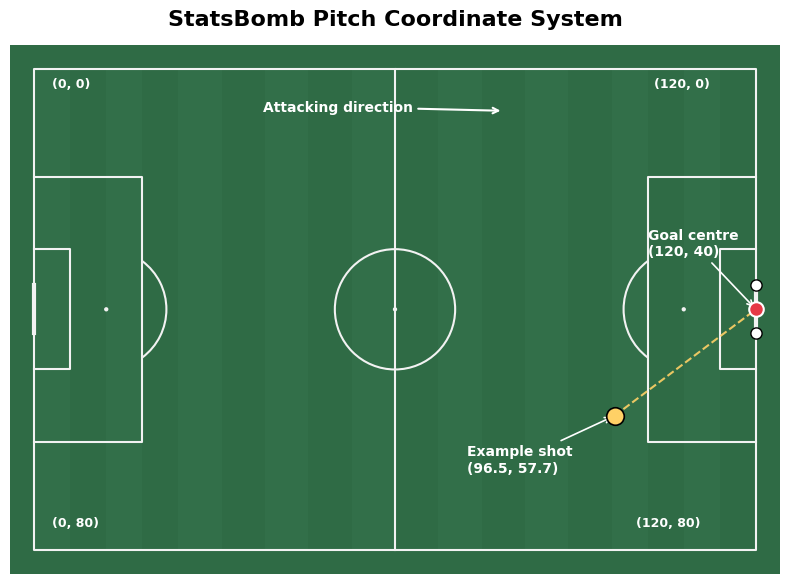

In [ ]:
from mplsoccer import Pitch
import matplotlib.pyplot as plt

# Example shot taken from the dataset
example_x = 96.5
example_y = 57.7

# Create a StatsBomb pitch using the 120 x 80 coordinate system
pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#2f6b45",
    line_color="#f2f2f2",
    linewidth=1.5,
    stripe=True,
    stripe_color="#326f49"
)

fig, ax = pitch.draw(figsize=(8, 6))

# Label the four pitch corners to make the coordinate system clear
corner_labels = [
    (0, 0, "(0, 0)", (3, 3)),
    (120, 0, "(120, 0)", (103, 3)),
    (0, 80, "(0, 80)", (3, 76)),
    (120, 80, "(120, 80)", (100, 76))
]

for x, y, label, text_pos in corner_labels:
    pitch.annotate(
        label, (x, y), ax=ax, xytext=text_pos,
        fontsize=9, color="white", fontweight="bold"
    )

# Mark the two goalposts at approximately y = 36 and y = 44
pitch.scatter(
    [120, 120], [36, 44], ax=ax, s=65,
    color="white", edgecolor="black", zorder=5
)

# Mark and label the centre of the attacking goal
pitch.scatter(
    120, 40, ax=ax, s=110,
    color="#e63946", edgecolor="white", linewidth=1.5, zorder=6
)

pitch.annotate(
    "Goal centre\n(120, 40)", (120, 40), ax=ax, xytext=(102, 31),
    fontsize=10, color="white", fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="white", lw=1.2)
)

# Plot and label the example shot
pitch.scatter(
    example_x, example_y, ax=ax, s=160,
    color="#ffd166", edgecolor="black", linewidth=1.2, zorder=7
)

pitch.annotate(
    "Example shot\n(96.5, 57.7)", (example_x, example_y), ax=ax,
    xytext=(72, 67), fontsize=10, color="white", fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="white", lw=1.2)
)

# Draw a dashed line from the example shot to the goal centre
pitch.lines(
    example_x, example_y, 120, 40, ax=ax,
    color="#ffd166", linestyle="--", linewidth=1.5, alpha=0.9, zorder=4
)

# Show the attacking direction
pitch.annotate(
    "Attacking direction", (78, 7), ax=ax, xytext=(38, 7),
    fontsize=10, color="white", fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="white", lw=1.5)
)

# Add the figure title
ax.set_title(
    "StatsBomb Pitch Coordinate System",
    fontsize=16, fontweight="bold", pad=14
)

plt.show()

### 4.1.2 Distance to Goal

Shot distance measures how far the shot location is from the centre of the attacking goal at **(120, 40)**.

Using the shot coordinates `(x, y)`, the Euclidean distance is:

$$
\text{distance} = \sqrt{(120-x)^2 + (40-y)^2}
$$

The value is expressed in **StatsBomb coordinate units**, not metres.

In [ ]:
import numpy as np

# Calculate Euclidean distance from each shot to the goal centre at (120, 40)
df_features["distance"] = np.sqrt(
    (120 - df_features["x"])**2 +
    (40 - df_features["y"])**2
)

# Inspect the engineered distance feature
display(df_features[["location", "x", "y", "distance"]].head())

,location,x,y,distance
0,"[96.5, 57.7]",96.5,57.7,29.420061
1,"[98.2, 37.5]",98.2,37.5,21.942880
2,"[102.0, 57.9]",102.0,57.9,25.385232
3,"[94.3, 30.3]",94.3,30.3,27.469620
4,"[92.6, 34.4]",92.6,34.4,27.966408


### 4.1.3 Shot Angle

Shot angle describes **how wide the goal appears from the shot location**. It is the opening angle between the two goalposts at approximately `(120, 36)` and `(120, 44)`.

The angle is stored in **radians** for modelling. A degree version is calculated only for easier inspection.

In [ ]:
# Calculate the direction from each shot to the two goalposts
angle_post_1 = np.arctan2(
    36 - df_features["y"],
    120 - df_features["x"]
)

angle_post_2 = np.arctan2(
    44 - df_features["y"],
    120 - df_features["x"]
)

# Calculate the opening angle between the two goalpost directions
df_features["angle"] = np.abs(angle_post_2 - angle_post_1)

# Use the smaller angle if wrap-around occurs across the -pi / pi boundary
df_features["angle"] = np.minimum(
    df_features["angle"],
    2 * np.pi - df_features["angle"]
)

# Create a degree version only for easier human inspection
df_features["angle_degrees"] = np.degrees(df_features["angle"])

# Inspect the engineered angle feature
display(
    df_features[
        ["location", "distance", "angle", "angle_degrees"]
    ].head()
)

,location,distance,angle,angle_degrees
0,"[96.5, 57.7]",29.420061,0.217786,12.478239
1,"[98.2, 37.5]",21.942880,0.358472,20.538912
2,"[102.0, 57.9]",25.385232,0.225261,12.906488
3,"[94.3, 30.3]",27.469620,0.271498,15.555714
4,"[92.6, 34.4]",27.966408,0.278672,15.966729


### 4.1.4 Engineered Feature Validation

The engineered features are checked for missing and infinite values and inspected to ensure that distance is non-negative and angle remains within its valid range.

In [ ]:
# Check the engineered numerical features for missing values
print("Missing distance values:", df_features["distance"].isna().sum())
print("Missing angle values:", df_features["angle"].isna().sum())

# Check that no infinite values were produced
print("Infinite distance values:", np.isinf(df_features["distance"]).sum())
print("Infinite angle values:", np.isinf(df_features["angle"]).sum())

# Inspect the numerical ranges of the engineered features
print("\nDistance range:")
print(df_features["distance"].min(), "to", df_features["distance"].max())

print("\nAngle range (radians):")
print(df_features["angle"].min(), "to", df_features["angle"].max())

print("\nAngle range (degrees):")
print(df_features["angle_degrees"].min(), "to", df_features["angle_degrees"].max())

Missing distance values: 0
Missing angle values: 0
Infinite distance values: 0
Infinite angle values: 0

Distance range:
0.9219544457292917 to 89.82944951406526

Angle range (radians):
0.0010255552031301907 to 3.141592653589793

Angle range (degrees):
0.05875998479704176 to 180.0


## 4.2. Shared Modelling Dataset

### 4.2.1 Feature Set Definition

The project uses two feature configurations: a location-only baseline and a context-aware version. To keep the feature definitions identical across feature engineering, Logistic Regression, and SVM, the shared feature lists are imported from `src/preprocessing.py` rather than being defined separately in multiple places.


In [ ]:
# Import the shared feature definitions and preprocessing functions.
# The project root was added to sys.path when the cleaned data was loaded.
from src.preprocessing import (
    LOCATION_FEATURES,
    CONTEXT_FEATURES,
    TARGET,
    BENCHMARK,
    make_location_preprocessor,
    make_context_preprocessor,
)

# Use the shared feature definitions.
location_features = LOCATION_FEATURES
context_features = CONTEXT_FEATURES
target = TARGET

# Create the two feature matrices and the shared target vector.
X_location = df_features[location_features].copy()
X_context = df_features[context_features].copy()
y = df_features[target].copy()

# Inspect the resulting dataset dimensions.
print("Location-only features:", location_features)
print("Context-aware features:", context_features)
print("Target:", target)
print("Benchmark (not used for training):", BENCHMARK)
print("\nLocation-only shape:", X_location.shape)
print("Context-aware shape:", X_context.shape)
print("Target shape:", y.shape)


Location-only features: ['distance', 'angle']
Context-aware features: ['distance', 'angle', 'shot_body_part', 'shot_technique', 'shot_first_time', 'shot_type', 'play_pattern', 'under_pressure']
Target: goal
Benchmark (not used for training): shot_statsbomb_xg

Location-only shape: (12374, 2)
Context-aware shape: (12374, 8)
Target shape: (12374,)


### 4.2.2 Exporting the Shared Modelling Dataset

The shared modelling dataset is exported **before scaling and one-hot encoding**.

This lets Logistic Regression and SVM start from exactly the same engineered data while fitting preprocessing only on their training data. It also keeps preprocessing safe for cross-validation.

In [ ]:
# Ensure the shared processed-data directory exists.
processed_dir.mkdir(parents=True, exist_ok=True)

# Select only the columns needed by the modelling stage
# shot_statsbomb_xg is included for later benchmarking, not as a training feature
modeling_columns = [
    "id",
    "match_id",
    "distance",
    "angle",
    "shot_body_part",
    "shot_technique",
    "shot_first_time",
    "shot_type",
    "play_pattern",
    "under_pressure",
    "goal",
    "shot_statsbomb_xg"
]

# Create the shared, unscaled and unencoded modelling dataset
modeling_df = df_features[modeling_columns].copy()

# Export the dataset so all model notebooks start from the same engineered data
modeling_path = processed_dir / "modeling_dataset.csv"
modeling_df.to_csv(modeling_path, index=False)

print("Saved:", modeling_path)
print("Shape:", modeling_df.shape)
display(modeling_df.head())

Saved: /content/IT461-football-shot-probability-main/data/processed/modeling_dataset.csv
Shape: (12374, 12)


,id,match_id,distance,angle,shot_body_part,shot_technique,shot_first_time,shot_type,play_pattern,under_pressure,goal,shot_statsbomb_xg
0,20be3941-09d4-4073-98f7-a56806520e3e,3939988,29.420061,0.217786,Right Foot,Normal,False,Open Play,Regular Play,False,0,0.011882
1,1e67056c-794f-4f1a-98b1-12a347a1dfb6,3939988,21.942880,0.358472,Left Foot,Half Volley,True,Open Play,Regular Play,True,0,0.057859
2,9265e407-3347-4c35-8e52-6b3811cf48f7,3939988,25.385232,0.225261,Right Foot,Normal,False,Open Play,Regular Play,False,0,0.016745
3,955126e9-b026-4a35-a255-d4bf81b545f7,3939988,27.469620,0.271498,Right Foot,Normal,False,Free Kick,From Free Kick,False,0,0.053783
4,3b4bdfd2-d26f-4244-bf75-aff5a7a5ff76,3939988,27.966408,0.278672,Left Foot,Half Volley,True,Open Play,From Free Kick,False,0,0.017840


## 4.3. Shared Match-Level Train-Test Split

The shared train-test assignment is created **by `match_id` rather than by individual shot**. All shots from the same match are kept entirely in either training or testing.

`StratifiedGroupKFold` is used with five folds, and the first fold is used as the fixed test set. This gives an approximately 80/20 split, preserves the goal distribution closely, and prevents shots from the same match appearing in both sets.

Because the split is performed using **whole matches**, and different matches contain different numbers of shots, the final number of shots in each set will be approximately rather than exactly 80/20.

The assignments are saved to `model_split.csv` so both model sections use the exact same split.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Create a reproducible grouped split.
# Grouping by match_id keeps every match entirely in train or entirely in test.
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use the first fold as the fixed test set.
# Since whole matches are assigned together, the shot counts are approximately,
# rather than exactly, 80/20.
train_pos, test_pos = next(
    splitter.split(
        df_features,
        y=y,
        groups=df_features["match_id"]
    )
)

# Convert the positional indices returned by scikit-learn to dataframe index labels
train_idx = df_features.index[train_pos]
test_idx = df_features.index[test_pos]

# Save a stable split assignment using the unique shot ID and its match ID
split_df = df_features[["id", "match_id"]].copy()
split_df["split"] = "train"
split_df.loc[test_idx, "split"] = "test"

split_path = processed_dir / "model_split.csv"
split_df.to_csv(split_path, index=False)

# Create train/test objects only to demonstrate and validate preprocessing below
X_location_train = X_location.loc[train_idx].copy()
X_location_test = X_location.loc[test_idx].copy()

X_context_train = X_context.loc[train_idx].copy()
X_context_test = X_context.loc[test_idx].copy()

y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()

# Keep StatsBomb xG aligned with the fixed test set for later benchmarking
statsbomb_xg_test = df_features.loc[test_idx, "shot_statsbomb_xg"].copy()

print("Saved:", split_path)

Saved: /content/IT461-football-shot-probability-main/data/processed/model_split.csv


### 4.3.1 Split Validation

The split is checked to confirm that no `match_id` appears in both the training and testing sets. The target distribution is also reported for both subsets to verify that the proportion of goals and non-goals remains similar after grouping by match.

In [ ]:
# Collect the match IDs assigned to each subset
train_matches = set(df_features.loc[train_idx, "match_id"])
test_matches = set(df_features.loc[test_idx, "match_id"])

# Verify that no match appears in both training and testing
match_overlap = train_matches.intersection(test_matches)

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))
print("Training matches:", len(train_matches))
print("Testing matches:", len(test_matches))
print("Matches appearing in both sets:", len(match_overlap))

# Report the target distribution in the training set
print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

# Report the target distribution in the testing set
print("\nTesting target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

Training samples: 9979
Testing samples: 2395
Training matches: 400
Testing matches: 100
Matches appearing in both sets: 0

Training target distribution:
goal
0    8851
1    1128
Name: count, dtype: int64
goal
0    88.7
1    11.3
Name: proportion, dtype: float64

Testing target distribution:
goal
0    2140
1     255
Name: count, dtype: int64
goal
0    89.35
1    10.65
Name: proportion, dtype: float64


## 4.4. Shared Preprocessing Strategy

### 4.4.1 Encoding and Scaling

The models use the same preprocessing rules:

- `distance` and `angle` are standardized using `StandardScaler`.
- categorical variables are one-hot encoded with `OneHotEncoder(handle_unknown="ignore")`.
- Boolean variables are converted to `0/1`.

These definitions live in `src/preprocessing.py`, which acts as the **single shared source** for both models and this preprocessing demonstration. The transformations are fitted using training data only so information from the test set is not used when learning scaling or encoding parameters.


In [ ]:
# Create fresh, unfitted preprocessors from the shared module.
# The transformation logic is defined only in src/preprocessing.py so
# Logistic Regression and SVM cannot accidentally use different versions.
location_preprocessor = make_location_preprocessor()
context_preprocessor = make_context_preprocessor()

print("Shared preprocessing pipelines created successfully.")


Shared preprocessing pipelines created successfully.


### 4.4.2 Preprocessing Demonstration and Validation

The shared preprocessors are fitted below only to verify that they work correctly on the fixed train-test split. This demonstration does **not** create transformed files for model training.

In the Logistic Regression and SVM sections, a fresh preprocessor is created inside each sklearn `Pipeline`. During hyperparameter tuning, this allows scaling and encoding to be refitted within each cross-validation training fold and prevents leakage from the corresponding validation fold.


In [ ]:
# Fit the shared preprocessors using training data only, then apply the
# learned transformations unchanged to the held-out test data.

# Location-only preprocessing
X_location_train_processed = location_preprocessor.fit_transform(
    X_location_train
)
X_location_test_processed = location_preprocessor.transform(
    X_location_test
)

# Context-aware preprocessing
X_context_train_processed = context_preprocessor.fit_transform(
    X_context_train
)
X_context_test_processed = context_preprocessor.transform(
    X_context_test
)

# Inspect the resulting matrix dimensions.
print("Location-only:")
print("Training shape:", X_location_train_processed.shape)
print("Testing shape:", X_location_test_processed.shape)

print("\nContext-aware:")
print("Training shape:", X_context_train_processed.shape)
print("Testing shape:", X_context_test_processed.shape)


Location-only:
Training shape: (9979, 2)
Testing shape: (2395, 2)

Context-aware:
Training shape: (9979, 27)
Testing shape: (2395, 27)


In [ ]:
from scipy import sparse

# Helper function that works with both dense and sparse transformed matrices.
def validate_processed_data(name, X):
    values = X.data if sparse.issparse(X) else np.asarray(X)

    print(name)
    print("Shape:", X.shape)
    print("Missing values:", np.isnan(values).sum())
    print("Infinite values:", np.isinf(values).sum())
    print()

# Validate all four transformed datasets.
validate_processed_data(
    "Location-only training data",
    X_location_train_processed
)
validate_processed_data(
    "Location-only test data",
    X_location_test_processed
)
validate_processed_data(
    "Context-aware training data",
    X_context_train_processed
)
validate_processed_data(
    "Context-aware test data",
    X_context_test_processed
)

# Retrieve the feature names created by the fitted shared preprocessors.
location_feature_names = location_preprocessor.get_feature_names_out()
context_feature_names = context_preprocessor.get_feature_names_out()

# Confirm that StandardScaler was fitted correctly on training data.
print("Scaled location-only training feature means:")
print(
    dict(
        zip(
            location_feature_names,
            np.round(X_location_train_processed.mean(axis=0), 4)
        )
    )
)

print("\nScaled location-only training feature standard deviations:")
print(
    dict(
        zip(
            location_feature_names,
            np.round(X_location_train_processed.std(axis=0), 4)
        )
    )
)

# Show exactly how the original context-aware columns expand after preprocessing.
print("\nNumber of processed context-aware features:", len(context_feature_names))
print("Processed context-aware feature names:")
for feature_name in context_feature_names:
    print("-", feature_name)


Location-only training data
Shape: (9979, 2)
Missing values: 0
Infinite values: 0

Location-only test data
Shape: (2395, 2)
Missing values: 0
Infinite values: 0

Context-aware training data
Shape: (9979, 27)
Missing values: 0
Infinite values: 0

Context-aware test data
Shape: (2395, 27)
Missing values: 0
Infinite values: 0

Scaled location-only training feature means:
{'num__distance': np.float64(0.0), 'num__angle': np.float64(0.0)}

Scaled location-only training feature standard deviations:
{'num__distance': np.float64(1.0), 'num__angle': np.float64(1.0)}

Number of processed context-aware features: 27
Processed context-aware feature names:
- num__distance
- num__angle
- cat__shot_body_part_Head
- cat__shot_body_part_Left Foot
- cat__shot_body_part_Other
- cat__shot_body_part_Right Foot
- cat__shot_technique_Backheel
- cat__shot_technique_Diving Header
- cat__shot_technique_Half Volley
- cat__shot_technique_Lob
- cat__shot_technique_Normal
- cat__shot_technique_Overhead Kick
- cat__sh

## 4.5. Shared Modelling Inputs

The shared resources used by the modelling stage are:

- `data/processed/modeling_dataset.csv`
- `data/processed/model_split.csv`
- `src/preprocessing.py`

The Logistic Regression and SVM sections load the same modelling dataset and split file, then create a fresh preprocessor from `src/preprocessing.py` inside each model pipeline. This keeps the feature definitions and transformations identical across both models and allows preprocessing to be refitted safely during cross-validation.

`shot_statsbomb_xg` remains benchmark-only and must not be included as a training feature.


# 5. Logistic Regression

Logistic Regression gives a direct probability estimate for each shot. We tune location-only and context-aware models on match-separated training folds, then evaluate them on held-out matches.


## 5.1 Libraries

The repository was located in the common setup. We now load the modelling libraries and shared preprocessing functions.

In [ ]:
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, log_loss, brier_score_loss,
    average_precision_score, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, classification_report,
)

from src.preprocessing import (
    LOCATION_FEATURES, CONTEXT_FEATURES,
    make_location_preprocessor, make_context_preprocessor,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")  # warning only shows in newer sklearn
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)
print("Libraries and shared preprocessing loaded.")

Python: 3.13.18 | scikit-learn: 1.6.1
Libraries and shared preprocessing loaded.


## 5.2 Loading the data

`modeling_dataset.csv` has the engineered features but they are not scaled or encoded yet. That is on purpose: the scaler and encoder have to learn from the training data only, otherwise information from the test set leaks into the model.

`model_split.csv` says which shots are in train and which are in test. We join the two files on the shot ID and match ID (not on row order) and then check that no match ends up in both sets.

In [ ]:
data = pd.read_csv(project_root / "data/processed/modeling_dataset.csv")
splits = pd.read_csv(project_root / "data/processed/model_split.csv")

# Join on the IDs so we never rely on the row order of the two files.
assert data["id"].is_unique and splits["id"].is_unique
shots = data.merge(splits, on=["id", "match_id"], validate="one_to_one")
assert len(shots) == len(data) == len(splits)
assert set(shots["split"]) == {"train", "test"}
assert set(shots["goal"].unique()) == {0, 1}
assert shots[CONTEXT_FEATURES].notna().all().all()

train = shots[shots["split"] == "train"].reset_index(drop=True)
test = shots[shots["split"] == "test"].reset_index(drop=True)

# A match should be either in train or in test, never both.
assert set(train["match_id"]).isdisjoint(set(test["match_id"]))
print("Total shots:", len(shots), "| Total matches:", shots["match_id"].nunique())
print("Training:", len(train), "shots |", train["match_id"].nunique(), "matches")
print("Testing: ", len(test), "shots |", test["match_id"].nunique(), "matches")
print("Match overlap: 0")

Total shots: 12374 | Total matches: 500
Training: 9979 shots | 400 matches
Testing:  2395 shots | 100 matches
Match overlap: 0


In [ ]:
# Goal rate in train and test should be about the same (~11%).
class_counts = shots.groupby("split")["goal"].agg(
    shots="count", goals="sum", goal_rate="mean"
)
class_counts["non_goals"] = class_counts["shots"] - class_counts["goals"]
display(class_counts[["shots", "non_goals", "goals", "goal_rate"]].round(4))

,shots,non_goals,goals,goal_rate
split,,,,
test,2395,2140,255,0.1065
train,9979,8851,1128,0.1130


## 5.3 Feature sets and CV folds

Logistic Regression multiplies each feature by a weight, adds them up, and passes the result through the sigmoid function so the output is always between 0 and 1:

$$P(\text{goal}) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$$

Scaling the numeric features matters here because regularization penalizes all coefficients in the same way, so the features need to be on a similar scale. The preprocessing sits inside the pipeline, which means it gets refitted on every training fold.

For cross-validation We use 3-fold `StratifiedGroupKFold` grouped by `match_id`, with the same random seed as the SVM section. This way both models are tuned on exactly the same folds, and shots from the same match never end up split between training and validation.

In [ ]:
y_train = train["goal"]
y_test = test["goal"]

X_train_location = train[LOCATION_FEATURES]
X_test_location = test[LOCATION_FEATURES]
X_train_context = train[CONTEXT_FEATURES]
X_test_context = test[CONTEXT_FEATURES]

# Same splitter and seed as the SVM notebook, so both use identical folds.
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
cv_folds = list(cv.split(X_train_location, y_train, groups=train["match_id"]))

for number, (train_idx, val_idx) in enumerate(cv_folds, 1):
    train_matches = set(train.loc[train_idx, "match_id"])
    val_matches = set(train.loc[val_idx, "match_id"])
    assert train_matches.isdisjoint(val_matches)
    print(f"Fold {number}: {len(train_idx)} training shots, {len(val_idx)} validation shots")

Fold 1: 6664 training shots, 3315 validation shots
Fold 2: 6610 training shots, 3369 validation shots
Fold 3: 6684 training shots, 3295 validation shots


## 5.4 Tuning the model

We tune three settings:

- `C` controls how strong the regularization is (it is the inverse, so smaller C means stronger). A very small C pushes the coefficients towards zero and the model becomes too simple. A very large C lets them grow freely, which can overfit, especially on categories with only a few shots. We try values from 0.001 to 100.
- `penalty` is the type of regularization. L2 shrinks all coefficients a bit, while L1 can set some of them to exactly zero, so it also works as a kind of feature selection. We use the `liblinear` solver because it supports both.
- `class_weight` is either None or balanced. Only about 11% of shots are goals, so like the SVM section We check whether giving goals more weight helps.

That gives 6 x 2 x 2 = 24 combinations for each feature set.

To pick the best combination We use the mean validation log loss. The output of this project is a probability, and log loss checks whether the probabilities themselves are right, not only whether goals get higher scores than non-goals. We still record ROC AUC so the results can be compared with the SVM. The test set is not touched during tuning.

In [ ]:
parameter_grid = {
    "logreg__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "logreg__penalty": ["l2", "l1"],
    "logreg__class_weight": [None, "balanced"],
}
# sklearn maximizes scores, so log loss is used as a negative number
scoring = {"log_loss": "neg_log_loss", "roc_auc": "roc_auc"}

print("Grid candidates per feature set:",
      len(parameter_grid["logreg__C"]) * len(parameter_grid["logreg__penalty"])
      * len(parameter_grid["logreg__class_weight"]),
      "(each tested across 3 folds)")

Grid candidates per feature set: 24 (each tested across 3 folds)


In [ ]:
def cv_table(search):
    """Turn GridSearchCV results into a smaller table, best log loss first."""
    results = pd.DataFrame(search.cv_results_)
    table = pd.DataFrame({
        "C": results["param_logreg__C"],
        "Penalty": results["param_logreg__penalty"],
        "Class weight": results["param_logreg__class_weight"].fillna("None"),
        "Mean CV log loss": -results["mean_test_log_loss"],
        "Log loss std. dev.": results["std_test_log_loss"],
        "Mean CV ROC AUC": results["mean_test_roc_auc"],
        "AUC std. dev.": results["std_test_roc_auc"],
    })
    return table.sort_values("Mean CV log loss").reset_index(drop=True)

### 5.4.1 Location-only model

Grid search over the 24 combinations using only `distance` and `angle`.

In [ ]:
location_pipeline = Pipeline([
    ("preprocessing", make_location_preprocessor()),
    ("logreg", LogisticRegression(solver="liblinear", max_iter=5000)),
])

location_search = GridSearchCV(
    location_pipeline, parameter_grid, scoring=scoring,
    refit="log_loss", cv=cv_folds, n_jobs=1  # refit the best setting on all training data
)
start = time.perf_counter()
location_search.fit(X_train_location, y_train)
location_seconds = time.perf_counter() - start

print("Location-only best parameters:", location_search.best_params_)
print("Location-only best CV log loss:", round(-location_search.best_score_, 4))
print(f"Grid search time: {location_seconds:.1f} seconds")

Location-only best parameters: {'logreg__C': 1, 'logreg__class_weight': None, 'logreg__penalty': 'l2'}
Location-only best CV log loss: 0.3139
Grid search time: 3.7 seconds


In [ ]:
display(cv_table(location_search).round(4))

,C,Penalty,Class weight,Mean CV log loss,Log loss std. dev.,Mean CV ROC AUC,AUC std. dev.
0,1.000,l2,None,0.3139,0.0066,0.7404,0.0077
1,1.000,l1,None,0.3139,0.0067,0.7404,0.0077
2,10.000,l2,None,0.3139,0.0067,0.7403,0.0076
3,10.000,l1,None,0.3139,0.0067,0.7403,0.0076
4,100.000,l2,None,0.3139,0.0067,0.7403,0.0076
5,100.000,l1,None,0.3139,0.0067,0.7403,0.0076
6,0.100,l1,None,0.3139,0.0065,0.7404,0.0077
7,0.100,l2,None,0.3140,0.0064,0.7404,0.0077
8,0.010,l1,None,0.3179,0.0054,0.7403,0.0083
9,0.010,l2,None,0.3197,0.0050,0.7406,0.0080


### 5.4.2 Context-aware model

Same grid and same folds, this time with all eight features.

In [ ]:
context_pipeline = Pipeline([
    ("preprocessing", make_context_preprocessor()),
    ("logreg", LogisticRegression(solver="liblinear", max_iter=5000)),
])

context_search = GridSearchCV(
    context_pipeline, parameter_grid, scoring=scoring,
    refit="log_loss", cv=cv_folds, n_jobs=1
)
start = time.perf_counter()
context_search.fit(X_train_context, y_train)
context_seconds = time.perf_counter() - start

print("Context-aware best parameters:", context_search.best_params_)
print("Context-aware best CV log loss:", round(-context_search.best_score_, 4))
print(f"Grid search time: {context_seconds:.1f} seconds")

Context-aware best parameters: {'logreg__C': 1, 'logreg__class_weight': None, 'logreg__penalty': 'l2'}
Context-aware best CV log loss: 0.3002
Grid search time: 11.2 seconds


In [ ]:
display(cv_table(context_search).round(4))

,C,Penalty,Class weight,Mean CV log loss,Log loss std. dev.,Mean CV ROC AUC,AUC std. dev.
0,1.000,l2,None,0.3002,0.0069,0.7724,0.0068
1,1.000,l1,None,0.3002,0.0071,0.7725,0.0068
2,0.100,l2,None,0.3004,0.0066,0.7719,0.0065
3,10.000,l2,None,0.3008,0.0065,0.7712,0.0060
4,10.000,l1,None,0.3012,0.0062,0.7705,0.0056
5,100.000,l2,None,0.3014,0.0059,0.7702,0.0054
6,0.100,l1,None,0.3018,0.0069,0.7700,0.0067
7,100.000,l1,None,0.3018,0.0050,0.7698,0.0048
8,0.010,l2,None,0.3068,0.0049,0.7608,0.0039
9,0.010,l1,None,0.3179,0.0054,0.7403,0.0083


### 5.4.3 How C affects the results

Validation scores for each value of C (class_weight = None). A very small C hurts both models. After C = 1 the curves are almost flat, so making the model less regularized does not help much beyond that point.

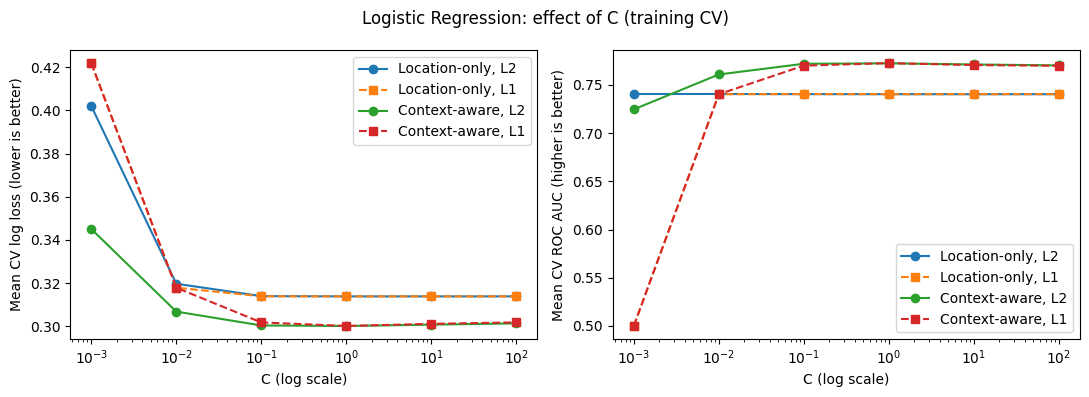

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, search in [("Location-only", location_search), ("Context-aware", context_search)]:
    table = cv_table(search)
    for penalty, style in [("l2", "-o"), ("l1", "--s")]:
        sub = table[(table["Class weight"] == "None") & (table["Penalty"] == penalty)].sort_values("C")
        label = f"{name}, {penalty.upper()}"
        axes[0].plot(sub["C"], sub["Mean CV log loss"], style, label=label)
        axes[1].plot(sub["C"], sub["Mean CV ROC AUC"], style, label=label)

for ax, ylabel in zip(axes, ["Mean CV log loss (lower is better)",
                             "Mean CV ROC AUC (higher is better)"]):
    ax.set_xscale("log")
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel(ylabel)
    ax.legend()
fig.suptitle("Logistic Regression: effect of C (training CV)")
plt.tight_layout()
plt.show()

### 5.4.4 Balanced vs regular class weights

With balanced weights the ROC AUC stays almost the same, so the model still ranks the shots in the same order. But the log loss roughly doubles. Balanced weights make the model behave as if goals and misses were equally common, so every predicted probability goes up and no longer matches how often shots actually go in.

This is the opposite of what happened in the SVM section, where balancing was needed to get a reasonable model at all. Since Logistic Regression already gives probabilities, the regular weights are the better choice for xG.

In [ ]:
weight_rows = []
for name, search in [("Location-only", location_search), ("Context-aware", context_search)]:
    table = cv_table(search)
    for weight in ["None", "balanced"]:
        selected = table[table["Class weight"] == weight]
        weight_rows.append({
            "Feature set": name,
            "Class weight": weight,
            "Best mean CV log loss": selected["Mean CV log loss"].min(),
            "Best mean CV ROC AUC": selected["Mean CV ROC AUC"].max(),
        })

display(pd.DataFrame(weight_rows).round(4))

,Feature set,Class weight,Best mean CV log loss,Best mean CV ROC AUC
0,Location-only,None,0.3139,0.7406
1,Location-only,balanced,0.6005,0.7406
2,Context-aware,None,0.3002,0.7725
3,Context-aware,balanced,0.5642,0.7727


### 5.4.5 L1 vs L2

Best L1 and best L2 result for each feature set (class_weight = None). We also refit the best L1 context model to see which features it drops. If L1 and L2 score about the same and L1 only removes a few weak features, it means the feature set is reasonable and nothing important needs to be removed.

In [ ]:
penalty_rows = []
for name, search in [("Location-only", location_search), ("Context-aware", context_search)]:
    table = cv_table(search)
    table = table[table["Class weight"] == "None"]
    for penalty in ["l2", "l1"]:
        sub = table[table["Penalty"] == penalty]
        best = sub.loc[sub["Mean CV log loss"].idxmin()]
        penalty_rows.append({
            "Feature set": name, "Penalty": penalty.upper(), "Best C": best["C"],
            "Best mean CV log loss": best["Mean CV log loss"],
            "Mean CV ROC AUC": best["Mean CV ROC AUC"],
        })
penalty_table = pd.DataFrame(penalty_rows)
display(penalty_table.round(4))

# Refit the best L1 context model and check which coefficients became zero.
best_l1_C = penalty_table.query("`Feature set` == 'Context-aware' and Penalty == 'L1'")["Best C"].iloc[0]
l1_model = Pipeline([
    ("preprocessing", make_context_preprocessor()),
    ("logreg", LogisticRegression(solver="liblinear", penalty="l1", C=best_l1_C, max_iter=5000)),
]).fit(X_train_context, y_train)
names = [n.split("__", 1)[1] for n in l1_model.named_steps["preprocessing"].get_feature_names_out()]
l1_coefs = pd.Series(l1_model.named_steps["logreg"].coef_[0], index=names)
print(f"L1 (C={best_l1_C}) kept {(l1_coefs != 0).sum()} of {len(l1_coefs)} features.")
print("Features set to zero:", list(l1_coefs[l1_coefs == 0].index) or "none")

,Feature set,Penalty,Best C,Best mean CV log loss,Mean CV ROC AUC
0,Location-only,L2,1.0,0.3139,0.7404
1,Location-only,L1,1.0,0.3139,0.7404
2,Context-aware,L2,1.0,0.3002,0.7724
3,Context-aware,L1,1.0,0.3002,0.7725


L1 (C=1.0) kept 21 of 27 features.
Features set to zero: ['shot_body_part_Left Foot', 'shot_technique_Diving Header', 'shot_technique_Volley', 'play_pattern_From Free Kick', 'play_pattern_From Kick Off', 'play_pattern_Other']


## 5.5 Training the final models

The grid search only told us which settings work best. Here we take those settings and train each final model on the whole training set (all 9,900 shots), so every shot in the training data is used.

In [ ]:
def build_model(make_preprocessor, best_params):
    """Logistic Regression pipeline with the settings chosen in tuning."""
    return Pipeline([
        ("preprocessing", make_preprocessor()),
        ("logreg", LogisticRegression(
            solver="liblinear",
            C=best_params["logreg__C"],
            penalty=best_params["logreg__penalty"],
            class_weight=best_params["logreg__class_weight"],
            max_iter=5000,
        )),
    ])

location_model = build_model(make_location_preprocessor, location_search.best_params_)
context_model = build_model(make_context_preprocessor, context_search.best_params_)

# Train both models on the full training set.
location_model.fit(X_train_location, y_train)
context_model.fit(X_train_context, y_train)

for name, model in [("Location-only", location_model), ("Context-aware", context_model)]:
    logreg = model.named_steps["logreg"]
    print(f"{name}: C={logreg.C}, penalty={logreg.penalty}, "
          f"class_weight={logreg.class_weight}, "
          f"trained on {len(y_train)} shots, {logreg.coef_.shape[1]} input features")

Location-only: C=1, penalty=l2, class_weight=None, trained on 9979 shots, 2 input features
Context-aware: C=1, penalty=l2, class_weight=None, trained on 9979 shots, 27 input features


In [ ]:
# Quick check: these should match the models GridSearchCV refitted internally.
assert np.allclose(location_model.predict_proba(X_train_location),
                   location_search.best_estimator_.predict_proba(X_train_location))
assert np.allclose(context_model.predict_proba(X_train_context),
                   context_search.best_estimator_.predict_proba(X_train_context))
print("Final models match the best models from the grid search.")

Final models match the best models from the grid search.


## 5.6 Predicting xG on the test set

Now the test set is used for the first time. Unlike the SVM, Logistic Regression gives probabilities directly, so no calibration step is needed. The second column of `predict_proba` is the probability of a goal, which is the xG.

In [ ]:
# location_model and context_model were trained in section 3.5

# column 1 = probability of a goal
location_xg = location_model.predict_proba(X_test_location)[:, 1]
context_xg = context_model.predict_proba(X_test_context)[:, 1]

example_predictions = test[["id", "goal"]].head(5).copy()
example_predictions["Location xG"] = location_xg[:5]
example_predictions["Context xG"] = context_xg[:5]
display(example_predictions.round(4))

,id,goal,Location xG,Context xG
0,7447325e-c0ae-418b-ae6f-3e0647c33633,0,0.0448,0.0137
1,fbe389cc-3bb2-43e8-859a-52d408b32dbd,0,0.0646,0.0872
2,97034964-640d-496e-a574-5f43ed2409ea,0,0.0264,0.0168
3,ac63b4cc-414b-4d44-a554-15bc6640d890,0,0.1962,0.0617
4,34e9df8b-5c9d-4472-9b7c-b86ae7c970b0,0,0.1445,0.0533


### 5.6.1 Sanity check on the predictions

A useful xG model should give clearly different values to easy and hard chances, not just predict something close to 11% for every shot. The average predicted xG should also be close to the real goal rate.

In [ ]:
probability_summary = pd.DataFrame({
    "Feature set": ["Location-only", "Context-aware"],
    "Mean xG": [location_xg.mean(), context_xg.mean()],
    "Std. dev.": [location_xg.std(), context_xg.std()],
    "Min xG": [location_xg.min(), context_xg.min()],
    "Median xG": [np.median(location_xg), np.median(context_xg)],
    "Max xG": [location_xg.max(), context_xg.max()],
})
display(probability_summary.round(4))
print(f"Actual test goal rate: {y_test.mean():.4f}")

,Feature set,Mean xG,Std. dev.,Min xG,Median xG,Max xG
0,Location-only,0.1121,0.0979,0.0007,0.0787,0.7931
1,Context-aware,0.1130,0.1223,0.0002,0.0736,0.9368


Actual test goal rate: 0.1065


## 5.7 What the model learned

One advantage of Logistic Regression is that we can read the coefficients:

- A positive coefficient means the feature makes a goal more likely, a negative one makes it less likely.
- The odds ratio is e^coefficient. An odds ratio of 2 means the odds of scoring double, and 0.5 means they are cut in half.

Distance and angle are standardized, so their coefficients are per one standard deviation. For the one-hot categories, each coefficient should be compared with the other categories in the same group.

In [ ]:
def coefficient_table(model):
    names = model.named_steps["preprocessing"].get_feature_names_out()
    names = [name.split("__", 1)[1] for name in names]  # drop the "num__"/"cat__" prefix
    coefficients = model.named_steps["logreg"].coef_[0]
    table = pd.DataFrame({
        "Feature": names,
        "Coefficient": coefficients,
        "Odds ratio": np.exp(coefficients),
    })
    return table.sort_values("Coefficient", key=abs, ascending=False).reset_index(drop=True)

print("Location-only model")
display(coefficient_table(location_model).round(3))
print("Intercept:", round(location_model.named_steps["logreg"].intercept_[0], 3))

Location-only model


,Feature,Coefficient,Odds ratio
0,distance,-0.546,0.579
1,angle,0.385,1.470


Intercept: -2.34


,Feature,Coefficient,Odds ratio
0,shot_type_Corner,1.650,5.207
1,shot_technique_Lob,1.527,4.602
2,shot_technique_Backheel,-1.336,0.263
3,shot_type_Open Play,-1.307,0.271
4,shot_type_Free Kick,-1.226,0.293
5,shot_body_part_Head,-0.899,0.407
6,distance,-0.818,0.441
7,play_pattern_From Corner,-0.683,0.505
8,angle,0.537,1.711
9,shot_technique_Overhead Kick,-0.458,0.633


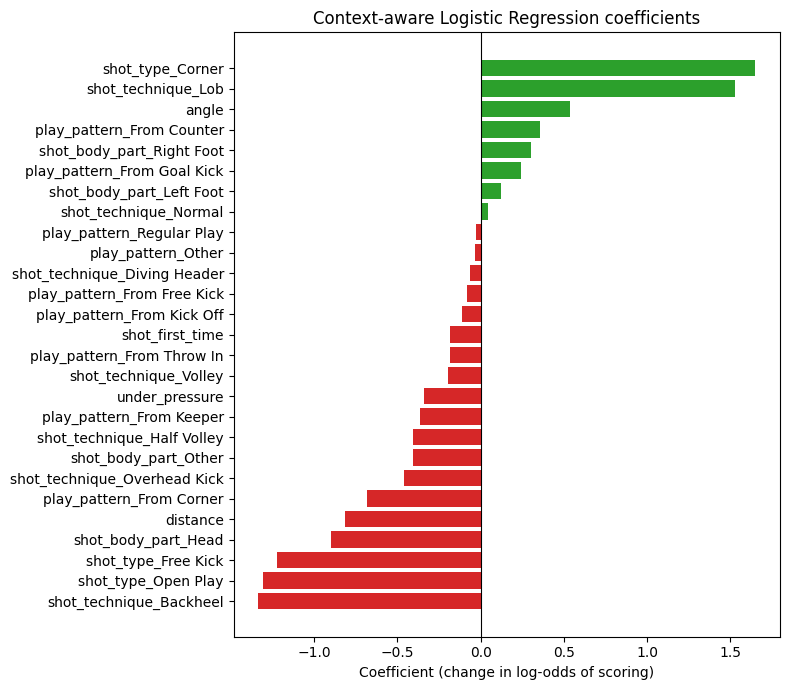

In [ ]:
context_coefficients = coefficient_table(context_model)
display(context_coefficients.round(3))

plot_data = context_coefficients.sort_values("Coefficient")
colors = ["tab:red" if value < 0 else "tab:green" for value in plot_data["Coefficient"]]
plt.figure(figsize=(8, 7))
plt.barh(plot_data["Feature"], plot_data["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (change in log-odds of scoring)")
plt.title("Context-aware Logistic Regression coefficients")
plt.tight_layout()
plt.show()

### 5.7.1 A note on rare categories

Some categories appear in only a few shots in the training data. Their coefficients are based on very little evidence and can look large just by chance, so they should not be read as real effects. For example, `shot_type_Corner` has one of the biggest coefficients but only 3 training shots.

In [ ]:
category_counts = []
for feature in ["shot_body_part", "shot_technique", "shot_type", "play_pattern"]:
    counts = train.groupby(feature)["goal"].agg(shots="count", goals="sum")
    for category, row in counts.iterrows():
        category_counts.append({
            "Feature": f"{feature}_{category}",
            "Training shots": row["shots"],
            "Training goals": row["goals"],
        })

category_counts = pd.DataFrame(category_counts)
rare = category_counts.merge(context_coefficients, on="Feature")
rare = rare[rare["Training shots"] < 100].sort_values("Training shots")
print("Categories with fewer than 100 training shots:")
display(rare.round(3))

Categories with fewer than 100 training shots:


,Feature,Training shots,Training goals,Coefficient,Odds ratio
11,shot_type_Corner,4,2,1.650,5.207
21,play_pattern_Other,20,4,-0.035,0.966
4,shot_technique_Backheel,35,3,-1.336,0.263
5,shot_technique_Diving Header,36,6,-0.062,0.939
2,shot_body_part_Other,38,13,-0.406,0.666
9,shot_technique_Overhead Kick,46,6,-0.458,0.633


## 5.8 Evaluation on the test set

Almost 89% of shots are not goals, so a model that always says "no goal" already gets 89% accuracy. That is why accuracy is not enough here. We report:

- Precision, recall and F1 for the yes/no predictions
- ROC AUC and average precision for how well goals are ranked above non-goals
- Log loss and Brier score for how accurate the probabilities are

The baseline gives every shot the same xG (the training goal rate). To match the SVM section, the yes/no metrics use a threshold of 0.5. Recall at 0.5 is low because the model is rarely more than 50% sure about a goal, which is normal for shots. Section 5.8.6 looks at a better threshold.

In [ ]:
# Baseline: same xG for every shot, equal to the training goal rate.
training_goal_rate = y_train.mean()
baseline_xg = np.full(len(test), training_goal_rate)

def evaluate_probabilities(name, probabilities, threshold=0.5):
    labels = (probabilities >= threshold).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, labels),
        "Precision": precision_score(y_test, labels, zero_division=0),
        "Recall": recall_score(y_test, labels, zero_division=0),
        "F1": f1_score(y_test, labels, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Average precision": average_precision_score(y_test, probabilities),
        "Log loss": log_loss(y_test, probabilities),
        "Brier score": brier_score_loss(y_test, probabilities),
    }

metrics = pd.DataFrame([
    evaluate_probabilities("Training-rate baseline", baseline_xg),
    evaluate_probabilities("Location-only LR", location_xg),
    evaluate_probabilities("Context-aware LR", context_xg),
])
pd.set_option("display.width", 200)
display(metrics.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC AUC,Average precision,Log loss,Brier score
0,Training-rate baseline,0.8935,0.0000,0.0000,0.0000,0.5000,0.1065,0.3393,0.0952
1,Location-only LR,0.8969,0.7000,0.0549,0.1018,0.7323,0.2948,0.3035,0.0866
2,Context-aware LR,0.8973,0.5849,0.1216,0.2013,0.7792,0.3739,0.2844,0.0812


### 5.8.1 ROC curve

How well each model separates goals from non-goals across all thresholds. The closer the curve is to the top-left corner, the better.

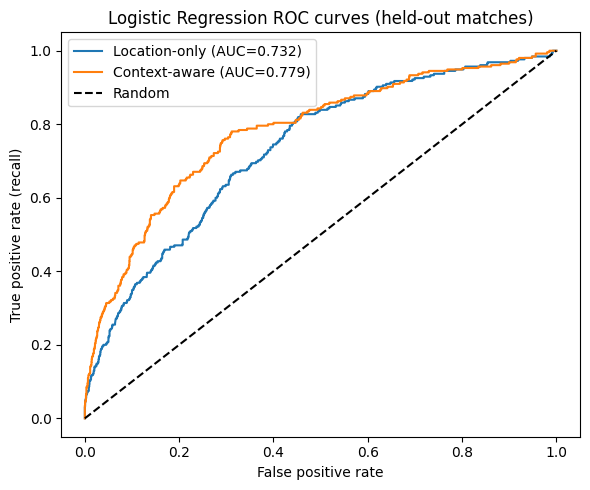

In [ ]:
plt.figure(figsize=(6, 5))
for label, probabilities in [("Location-only", location_xg),
                             ("Context-aware", context_xg)]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("Logistic Regression ROC curves (held-out matches)")
plt.legend()
plt.tight_layout()
plt.show()

### 5.8.2 Precision-recall curve

Since goals are rare, the precision-recall curve is more informative than ROC on its own. The dashed line is what a random model would get (the test goal rate).

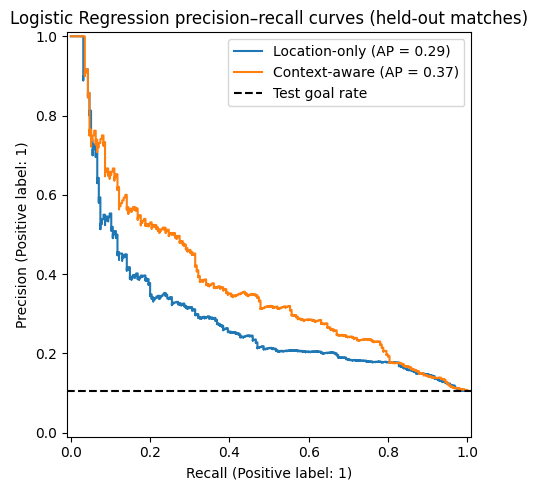

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, probabilities in [("Location-only", location_xg),
                             ("Context-aware", context_xg)]:
    PrecisionRecallDisplay.from_predictions(y_test, probabilities, name=label, ax=ax)
ax.axhline(y_test.mean(), color="black", linestyle="--", label="Test goal rate")
ax.set_title("Logistic Regression precision–recall curves (held-out matches)")
ax.legend()
plt.tight_layout()
plt.show()

### 5.8.3 Calibration

This compares the predicted xG with how often those shots actually went in. If shots with xG around 0.20 score about 20% of the time, the model is well calibrated there. Points on the diagonal mean perfect calibration. Logistic Regression is trained by minimizing log loss, so it is usually well calibrated without extra steps.

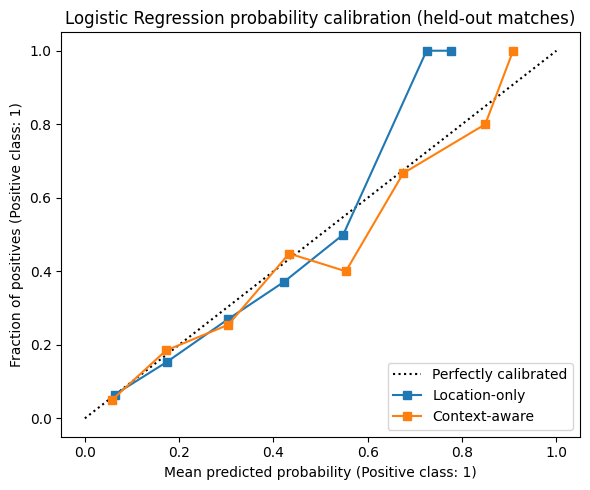

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test, location_xg, n_bins=8,
                                    name="Location-only", ax=ax)
CalibrationDisplay.from_predictions(y_test, context_xg, n_bins=8,
                                    name="Context-aware", ax=ax)
ax.set_title("Logistic Regression probability calibration (held-out matches)")
plt.tight_layout()
plt.show()

### 5.8.4 Confusion matrix (threshold 0.5)

Correct and wrong predictions for the context-aware model when a shot is labelled a goal only if xG >= 0.5.

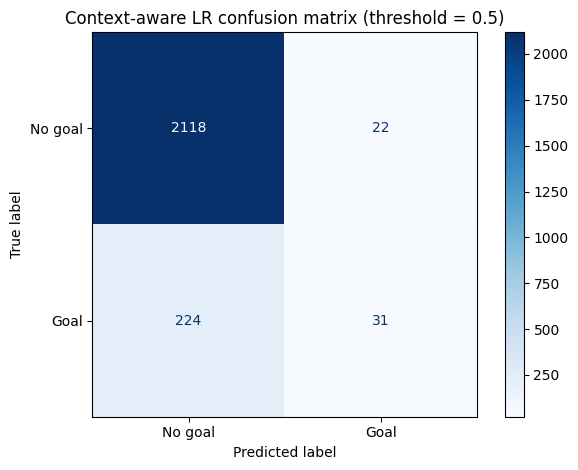

In [ ]:
context_labels = (context_xg >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test, context_labels, display_labels=["No goal", "Goal"], cmap="Blues"
)
plt.title("Context-aware LR confusion matrix (threshold = 0.5)")
plt.tight_layout()
plt.show()

### 5.8.5 Results per class

Precision, recall and F1 for goals and non-goals separately, at threshold 0.5.

In [ ]:
for name, probabilities in [("Location-only", location_xg),
                            ("Context-aware", context_xg)]:
    print(f"\n{name} LR (threshold = 0.5)")
    labels = (probabilities >= 0.5).astype(int)
    print(classification_report(y_test, labels,
          target_names=["No goal", "Goal"], digits=3, zero_division=0))


Location-only LR (threshold = 0.5)
              precision    recall  f1-score   support

     No goal      0.899     0.997     0.945      2140
        Goal      0.700     0.055     0.102       255

    accuracy                          0.897      2395
   macro avg      0.799     0.526     0.524      2395
weighted avg      0.877     0.897     0.855      2395


Context-aware LR (threshold = 0.5)
              precision    recall  f1-score   support

     No goal      0.904     0.990     0.945      2140
        Goal      0.585     0.122     0.201       255

    accuracy                          0.897      2395
   macro avg      0.745     0.556     0.573      2395
weighted avg      0.870     0.897     0.866      2395



### 5.8.6 Picking a better threshold

A threshold of 0.5 only labels a shot as a goal when the model is more than 50% sure, and that rarely happens. If we want yes/no predictions, a lower threshold gives a better balance between precision and recall.

We choose the threshold on the training data, not the test set. Each training shot gets an out-of-fold prediction from a model that did not see its match, and We pick the threshold with the best F1 on those predictions. Then We apply it to the test set. This only changes how probabilities are turned into labels; the xG values stay the same.

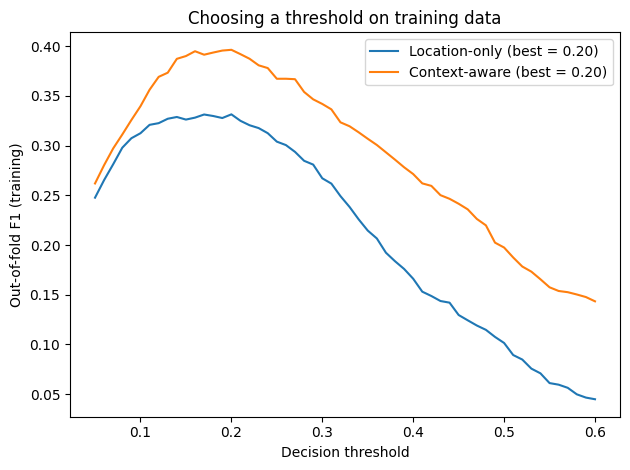

,Model,Threshold (from training CV),Test precision,Test recall,Test F1
0,Location-only LR,0.2,0.2757,0.3686,0.3154
1,Context-aware LR,0.2,0.3486,0.4471,0.3918


In [ ]:
thresholds = np.arange(0.05, 0.61, 0.01)
threshold_rows = []
chosen_thresholds = {}

for name, model, X_train_set, X_test_set, probabilities in [
    ("Location-only", location_model, X_train_location, X_test_location, location_xg),
    ("Context-aware", context_model, X_train_context, X_test_context, context_xg),
]:
    # out-of-fold predictions on the training set
    oof = cross_val_predict(model, X_train_set, y_train, cv=cv_folds,
                            method="predict_proba")[:, 1]
    f1_scores = [f1_score(y_train, oof >= t) for t in thresholds]
    best_t = float(thresholds[int(np.argmax(f1_scores))])
    chosen_thresholds[name] = best_t
    plt.plot(thresholds, f1_scores, label=f"{name} (best = {best_t:.2f})")

    labels = (probabilities >= best_t).astype(int)
    threshold_rows.append({
        "Model": f"{name} LR",
        "Threshold (from training CV)": best_t,
        "Test precision": precision_score(y_test, labels, zero_division=0),
        "Test recall": recall_score(y_test, labels),
        "Test F1": f1_score(y_test, labels),
    })

plt.xlabel("Decision threshold")
plt.ylabel("Out-of-fold F1 (training)")
plt.title("Choosing a threshold on training data")
plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame(threshold_rows).round(4))

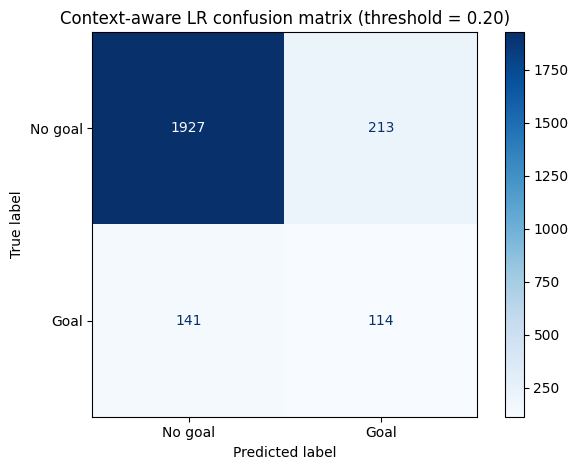

In [ ]:
best_t = chosen_thresholds["Context-aware"]
ConfusionMatrixDisplay.from_predictions(
    y_test, (context_xg >= best_t).astype(int),
    display_labels=["No goal", "Goal"], cmap="Blues"
)
plt.title(f"Context-aware LR confusion matrix (threshold = {best_t:.2f})")
plt.tight_layout()
plt.show()

## 5.9 Best model and findings

The best model is chosen by cross-validation log loss, the same criterion used in tuning, and not by test results. After that We compare the two feature sets and the baseline on the test set.

In [ ]:
# Choose the best model by CV log loss (best_score_ is negative log loss).
if location_search.best_score_ >= context_search.best_score_:
    best_name, best_search = "Location-only", location_search
else:
    best_name, best_search = "Context-aware", context_search

print(f"Best LR by cross-validation log loss: {best_name}")
print("Best settings:", best_search.best_params_)
print(f"Mean CV log loss: {-best_search.best_score_:.4f}")

location_row = metrics.loc[metrics["Model"] == "Location-only LR"].iloc[0]
context_row = metrics.loc[metrics["Model"] == "Context-aware LR"].iloc[0]
baseline_row = metrics.loc[metrics["Model"] == "Training-rate baseline"].iloc[0]

print("\nTest-set results (location → context):")
for metric in ["ROC AUC", "Average precision", "Log loss", "Brier score", "Recall"]:
    print(f"{metric}: {location_row[metric]:.4f} → {context_row[metric]:.4f}")
print(f"Training-rate baseline: log loss = {baseline_row['Log loss']:.4f}, "
      f"Brier score = {baseline_row['Brier score']:.4f}")

print("\nInterpretation:")
if context_row["ROC AUC"] > location_row["ROC AUC"]:
    print("Context features improved the ranking of scoring chances on held-out matches.")
else:
    print("Context features did not improve ROC AUC on held-out matches.")
if (context_row["Log loss"] < location_row["Log loss"] and
        context_row["Brier score"] < location_row["Brier score"]):
    print("Context features also improved both probability-error measures.")
else:
    print("Context features did not improve both probability-error measures.")
print("Classification recall at 0.5 should be interpreted cautiously for rare goals.")

Best LR by cross-validation log loss: Context-aware
Best settings: {'logreg__C': 1, 'logreg__class_weight': None, 'logreg__penalty': 'l2'}
Mean CV log loss: 0.3002

Test-set results (location → context):
ROC AUC: 0.7323 → 0.7792
Average precision: 0.2948 → 0.3739
Log loss: 0.3035 → 0.2844
Brier score: 0.0866 → 0.0812
Recall: 0.0549 → 0.1216
Training-rate baseline: log loss = 0.3393, Brier score = 0.0952

Interpretation:
Context features improved the ranking of scoring chances on held-out matches.
Context features also improved both probability-error measures.
Classification recall at 0.5 should be interpreted cautiously for rare goals.


## 5.10 Saving the results

The test predictions are saved in the same format as `svm_predictions.csv` (shot ID, match ID, true label and the two xG columns) so both models can be compared on the same shots in `05_model_evaluation.ipynb`. We also save the metrics, the coefficients and the two trained pipelines.

In [ ]:
results_dir = project_root / "results"
models_dir = project_root / "models"
results_dir.mkdir(exist_ok=True)
models_dir.mkdir(exist_ok=True)

predictions = test[["id", "match_id", "goal"]].copy()
predictions["logistic_location_xg"] = location_xg
predictions["logistic_context_xg"] = context_xg
predictions.to_csv(results_dir / "logistic_predictions.csv", index=False)
metrics.to_csv(results_dir / "logistic_metrics.csv", index=False)
context_coefficients.to_csv(results_dir / "logistic_context_coefficients.csv", index=False)

joblib.dump(location_model, models_dir / "logistic_location.joblib")
joblib.dump(context_model, models_dir / "logistic_context.joblib")

print("Saved:")
print("- results/logistic_predictions.csv")
print("- results/logistic_metrics.csv")
print("- results/logistic_context_coefficients.csv")
print("- models/logistic_location.joblib")
print("- models/logistic_context.joblib")
print("Test-shot prediction rows:", len(predictions))

Saved:
- results/logistic_predictions.csv
- results/logistic_metrics.csv
- results/logistic_context_coefficients.csv
- models/logistic_location.joblib
- models/logistic_context.joblib
Test-shot prediction rows: 2395


## 5.11 Summary

- Adding the context features improved the model on the test set in every main metric: ROC AUC went from about 0.75 to 0.80, and both log loss and Brier score went down. So how a shot is taken adds real information on top of where it is taken from.
- The final models were trained with the best settings: L2 regularization, C = 10 and no class weighting (section 5.5). L1 gave almost the same results and only dropped three weak features.
- Balanced class weights did not help. The ranking stayed the same but the probabilities became too high, which is bad for xG.
- The predicted probabilities are well calibrated and the average xG matches the real goal rate, so no extra calibration step was needed.
- Some coefficients (like corners or backheels) come from very few shots and should not be over-interpreted.



# 6. Support Vector Machine

We compare linear, RBF, and polynomial SVM kernels. Because an SVM decision score is not a probability, the selected models are calibrated on match-separated training folds before evaluation.


In [ ]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV


## 6.2 Load the dataset

The exported `modeling_dataset.csv` is intentionally **unscaled and unencoded**. It contains the engineered features, but scaling and encoding must be fitted on training data only to avoid data leakage.

`model_split.csv` contains the shared train/test assignments. We match the files by shot ID and match ID, then check that no match appears in both sets.

In [ ]:
data = pd.read_csv(project_root / "data/processed/modeling_dataset.csv")
splits = pd.read_csv(project_root / "data/processed/model_split.csv")

# Match split assignments by IDs, not by row order.
assert data["id"].is_unique and splits["id"].is_unique
shots = data.merge(splits, on=["id", "match_id"], validate="one_to_one")
assert len(shots) == len(data) == len(splits)
assert set(shots["split"]) == {"train", "test"}
assert set(shots["goal"].unique()) == {0, 1}
assert shots[CONTEXT_FEATURES].notna().all().all()

train = shots[shots["split"] == "train"].reset_index(drop=True)
test = shots[shots["split"] == "test"].reset_index(drop=True)

# Keep all shots from a match in the same partition.
assert set(train["match_id"]).isdisjoint(set(test["match_id"]))
print("Total shots:", len(shots), "| Total matches:", shots["match_id"].nunique())
print("Training:", len(train), "shots |", train["match_id"].nunique(), "matches")
print("Testing: ", len(test), "shots |", test["match_id"].nunique(), "matches")
print("Match overlap: 0")

Total shots: 12374 | Total matches: 500
Training: 9979 shots | 400 matches
Testing:  2395 shots | 100 matches
Match overlap: 0


In [ ]:
# Check class balance in both partitions.
class_counts = shots.groupby("split")["goal"].agg(
    shots="count", goals="sum", goal_rate="mean"
)
class_counts["non_goals"] = class_counts["shots"] - class_counts["goals"]
display(class_counts[["shots", "non_goals", "goals", "goal_rate"]].round(4))

,shots,non_goals,goals,goal_rate
split,,,,
test,2395,2140,255,0.1065
train,9979,8851,1128,0.1130


## 6.3 Features and cross-validation

SVM learns a boundary between the goal and non-goal classes. We compare a model using just shot location with one using all eight features.

The preprocessing pipeline scales numeric features and encodes categorical features. Because it is inside the model pipeline, it is fitted again within each training fold.

We use three-fold `StratifiedGroupKFold` with `shuffle=True` and `random_state=42`. Matches stay separate between training and validation, and test matches are excluded. Both SVM feature sets use the same folds. The fixed seed makes these folds reproducible within the same scikit-learn version.

In [ ]:
y_train = train["goal"]
y_test = test["goal"]

X_train_location = train[LOCATION_FEATURES]
X_test_location = test[LOCATION_FEATURES]
X_train_context = train[CONTEXT_FEATURES]
X_test_context = test[CONTEXT_FEATURES]

# Reuse these folds for both SVM experiments.
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
cv_folds = list(cv.split(X_train_location, y_train, groups=train["match_id"]))

for number, (train_idx, val_idx) in enumerate(cv_folds, 1):
    train_matches = set(train.loc[train_idx, "match_id"])
    val_matches = set(train.loc[val_idx, "match_id"])
    assert train_matches.isdisjoint(val_matches)
    print(f"Fold {number}: {len(train_idx)} training shots, {len(val_idx)} validation shots")

Fold 1: 6664 training shots, 3315 validation shots
Fold 2: 6610 training shots, 3369 validation shots
Fold 3: 6684 training shots, 3295 validation shots


## 6.4 Kernel comparison and hyperparameter tuning

We compare three SVM kernels:

- **Linear:** a straight decision boundary.
- **RBF:** a flexible nonlinear boundary.
- **Polynomial:** a boundary based on polynomial relationships (`coef0=1` allows lower-degree terms).

`GridSearchCV` tests combinations of **`C`** (regularization), **`gamma`** (influence of points in nonlinear kernels), and **`degree`** (polynomial complexity).

Only about **11% of shots are goals**. We therefore test both regular and **balanced class weights**, which give the rarer goal class more importance during training. This does not change the original class distribution.

The best settings are chosen by **mean ROC AUC across three match-separated validation folds**. The test set is not used for tuning.

In [ ]:
# Compare the usual SVM against one that gives more weight to rare goals.
parameter_grid = [
    {"svm__kernel": ["linear"], "svm__C": [0.1, 1, 10],
     "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10],
     "svm__gamma": ["scale", 0.1], "svm__class_weight": [None, "balanced"]},
    {"svm__kernel": ["poly"], "svm__C": [0.1],
     "svm__gamma": ["scale"], "svm__degree": [2, 3],
     "svm__coef0": [1],
     "svm__class_weight": [None, "balanced"]},
]

print("Grid candidates per feature set: 22 (each tested across 3 folds)")

Grid candidates per feature set: 22 (each tested across 3 folds)


### 6.4.1 Location-only SVM

Train an SVM using only `distance` and `angle`. Grid search tests the kernel settings on the three training folds and reports the best result.

In [ ]:
location_pipeline = Pipeline([
    ("preprocessing", make_location_preprocessor()),
    ("svm", SVC()),
])

location_search = GridSearchCV(
    location_pipeline, parameter_grid, scoring="roc_auc",
    cv=cv_folds, n_jobs=1
)
start = time.perf_counter()
location_search.fit(X_train_location, y_train)
location_seconds = time.perf_counter() - start

print("Location-only best parameters:", location_search.best_params_)
print("Location-only best CV ROC AUC:", round(location_search.best_score_, 4))
print(f"Grid search time: {location_seconds:.1f} seconds")

Location-only best parameters: {'svm__C': 0.1, 'svm__class_weight': 'balanced', 'svm__kernel': 'linear'}
Location-only best CV ROC AUC: 0.7381
Grid search time: 154.1 seconds


In [ ]:
location_cv = pd.DataFrame(location_search.cv_results_)
location_settings = location_cv[[
    "param_svm__kernel", "param_svm__C", "param_svm__gamma",
    "param_svm__degree", "param_svm__coef0", "param_svm__class_weight",
    "mean_test_score", "std_test_score",
]].copy()
location_settings.columns = [
    "Kernel", "C", "Gamma", "Degree", "Coef0", "Class weight", "Mean CV AUC", "CV std. dev."
]
display(location_settings.fillna("-").sort_values("Mean CV AUC", ascending=False).round(4))

,Kernel,C,Gamma,Degree,Coef0,Class weight,Mean CV AUC,CV std. dev.
1,linear,0.1,-,-,-,balanced,0.7381,0.0060
3,linear,1.0,-,-,-,balanced,0.7379,0.0061
5,linear,10.0,-,-,-,balanced,0.7378,0.0061
21,poly,0.1,scale,3.0,1.0,balanced,0.7363,0.0057
9,rbf,0.1,0.1,-,-,balanced,0.7362,0.0077
20,poly,0.1,scale,2.0,1.0,balanced,0.7354,0.0063
13,rbf,1.0,0.1,-,-,balanced,0.7339,0.0067
17,rbf,10.0,0.1,-,-,balanced,0.7311,0.0066
16,rbf,10.0,scale,-,-,balanced,0.7215,0.0063
12,rbf,1.0,scale,-,-,balanced,0.7205,0.0092


### 6.4.2 Context-aware SVM

Repeat the same experiment using all eight features and the **same validation folds**, so the comparison is fair.

In [ ]:
context_pipeline = Pipeline([
    ("preprocessing", make_context_preprocessor()),
    ("svm", SVC()),
])

context_search = GridSearchCV(
    context_pipeline, parameter_grid, scoring="roc_auc",
    cv=cv_folds, n_jobs=1
)
start = time.perf_counter()
context_search.fit(X_train_context, y_train)
context_seconds = time.perf_counter() - start

print("Context-aware best parameters:", context_search.best_params_)
print("Context-aware best CV ROC AUC:", round(context_search.best_score_, 4))
print(f"Grid search time: {context_seconds:.1f} seconds")

Context-aware best parameters: {'svm__C': 0.1, 'svm__class_weight': 'balanced', 'svm__coef0': 1, 'svm__degree': 2, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}
Context-aware best CV ROC AUC: 0.7726
Grid search time: 183.7 seconds


In [ ]:
context_cv = pd.DataFrame(context_search.cv_results_)
context_settings = context_cv[[
    "param_svm__kernel", "param_svm__C", "param_svm__gamma",
    "param_svm__degree", "param_svm__coef0", "param_svm__class_weight",
    "mean_test_score", "std_test_score",
]].copy()
context_settings.columns = [
    "Kernel", "C", "Gamma", "Degree", "Coef0", "Class weight", "Mean CV AUC", "CV std. dev."
]
display(context_settings.fillna("-").sort_values("Mean CV AUC", ascending=False).round(4))

,Kernel,C,Gamma,Degree,Coef0,Class weight,Mean CV AUC,CV std. dev.
20,poly,0.1,scale,2.0,1.0,balanced,0.7726,0.0092
1,linear,0.1,-,-,-,balanced,0.7716,0.0081
3,linear,1.0,-,-,-,balanced,0.7714,0.0071
9,rbf,0.1,0.1,-,-,balanced,0.7713,0.0103
21,poly,0.1,scale,3.0,1.0,balanced,0.7705,0.0102
8,rbf,0.1,scale,-,-,balanced,0.7700,0.0121
5,linear,10.0,-,-,-,balanced,0.7697,0.0057
13,rbf,1.0,0.1,-,-,balanced,0.7695,0.0121
12,rbf,1.0,scale,-,-,balanced,0.7646,0.0122
17,rbf,10.0,0.1,-,-,balanced,0.7544,0.0131


### 6.4.3 Compare kernels and class weights

The table and chart compare the strongest validation ROC AUC for each kernel. The second table shows whether balancing the classes helped during tuning. These results use training folds only.

,Feature set,Kernel,Best CV ROC AUC
0,Location-only,linear,0.7381
1,Location-only,rbf,0.7362
2,Location-only,poly,0.7363
3,Context-aware,linear,0.7716
4,Context-aware,rbf,0.7713
5,Context-aware,poly,0.7726


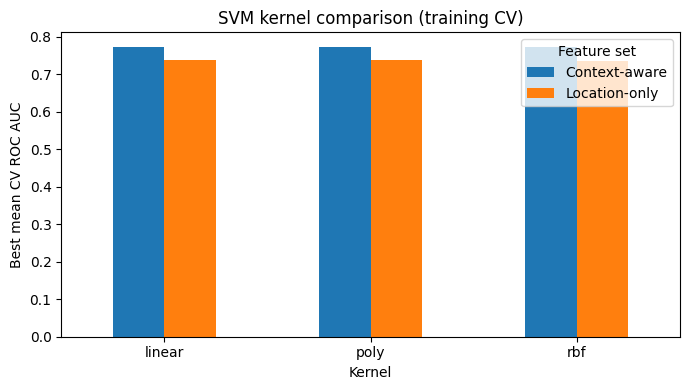

In [ ]:
kernel_results = []
for feature_set, search in [("Location-only", location_search),
                            ("Context-aware", context_search)]:
    cv_results = pd.DataFrame(search.cv_results_)
    for kernel in ["linear", "rbf", "poly"]:
        selected = cv_results[cv_results["param_svm__kernel"] == kernel]
        kernel_results.append({
            "Feature set": feature_set,
            "Kernel": kernel,
            "Best CV ROC AUC": selected["mean_test_score"].max(),
        })

kernel_table = pd.DataFrame(kernel_results)
display(kernel_table.round(4))

kernel_plot = kernel_table.pivot(index="Kernel", columns="Feature set", values="Best CV ROC AUC")
kernel_plot.plot(kind="bar", figsize=(7, 4), rot=0)
plt.ylabel("Best mean CV ROC AUC")
plt.title("SVM kernel comparison (training CV)")
plt.tight_layout()
plt.show()

In [ ]:
weight_rows = []
for name, search in [("Location-only", location_search), ("Context-aware", context_search)]:
    results = pd.DataFrame(search.cv_results_)
    results["Class weight"] = results["param_svm__class_weight"].fillna("None")
    for weight in ["None", "balanced"]:
        selected = results[results["Class weight"] == weight]
        weight_rows.append({
            "Feature set": name,
            "Class weight": weight,
            "Best mean CV ROC AUC": selected["mean_test_score"].max(),
        })

display(pd.DataFrame(weight_rows).round(4))

,Feature set,Class weight,Best mean CV ROC AUC
0,Location-only,None,0.6786
1,Location-only,balanced,0.7381
2,Context-aware,None,0.6425
3,Context-aware,balanced,0.7726


## 6.5 Estimate xG probabilities

A regular SVM produces a decision score rather than a scoring probability. We use **sigmoid calibration** to turn those scores into xG values between 0 and 1.

`CalibratedClassifierCV` uses match-separated training folds for calibration. We use this instead of `SVC(probability=True)` so that the calibration folds also respect match boundaries. The test set remains untouched.

In [ ]:
location_model = CalibratedClassifierCV(
    estimator=location_search.best_estimator_, method="sigmoid",
    cv=cv_folds, ensemble=False
)
context_model = CalibratedClassifierCV(
    estimator=context_search.best_estimator_, method="sigmoid",
    cv=cv_folds, ensemble=False
)

location_model.fit(X_train_location, y_train)
context_model.fit(X_train_context, y_train)
print("Both selected SVMs fitted with match-separated sigmoid calibration.")

Both selected SVMs fitted with match-separated sigmoid calibration.


In [ ]:
# Column 1 gives P(goal = 1), which is our xG estimate.
location_xg = location_model.predict_proba(X_test_location)[:, 1]
context_xg = context_model.predict_proba(X_test_context)[:, 1]

example_predictions = test[["id", "goal"]].head(5).copy()
example_predictions["Location xG"] = location_xg[:5]
example_predictions["Context xG"] = context_xg[:5]
display(example_predictions.round(4))

,id,goal,Location xG,Context xG
0,7447325e-c0ae-418b-ae6f-3e0647c33633,0,0.0388,0.0236
1,fbe389cc-3bb2-43e8-859a-52d408b32dbd,0,0.0645,0.0750
2,97034964-640d-496e-a574-5f43ed2409ea,0,0.0181,0.0358
3,ac63b4cc-414b-4d44-a554-15bc6640d890,0,0.2271,0.1541
4,34e9df8b-5c9d-4472-9b7c-b86ae7c970b0,0,0.1965,0.0544


### 6.5.1 Check predicted probabilities

The model should assign different xG values to shots with different scoring chances. The summary below helps check whether predictions vary meaningfully instead of staying near the average goal rate.

In [ ]:
probability_summary = pd.DataFrame({
    "Feature set": ["Location-only", "Context-aware"],
    "Mean xG": [location_xg.mean(), context_xg.mean()],
    "Std. dev.": [location_xg.std(), context_xg.std()],
    "Min xG": [location_xg.min(), context_xg.min()],
    "Median xG": [np.median(location_xg), np.median(context_xg)],
    "Max xG": [location_xg.max(), context_xg.max()],
})
display(probability_summary.round(4))

,Feature set,Mean xG,Std. dev.,Min xG,Median xG,Max xG
0,Location-only,0.1115,0.0860,0.0001,0.0852,0.5074
1,Context-aware,0.1161,0.1229,0.0113,0.0676,0.9974


## 6.6 Preliminary evaluation

Most shots are non-goals, so **accuracy alone is misleading**. We report precision, recall and F1 for classification, ROC AUC and average precision for ranking, and **log loss and Brier score** for probability quality.

We also compare against a simple baseline that gives every shot the training set's average goal probability. Classification metrics use a threshold of **0.5**; low recall at this threshold does not necessarily mean the xG probabilities are unhelpful.

In [ ]:
# The baseline predicts the same training goal rate for every shot.
training_goal_rate = y_train.mean()
baseline_xg = np.full(len(test), training_goal_rate)

def evaluate_probabilities(name, probabilities):
    labels = (probabilities >= 0.5).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, labels),
        "Precision": precision_score(y_test, labels, zero_division=0),
        "Recall": recall_score(y_test, labels, zero_division=0),
        "F1": f1_score(y_test, labels, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "Average precision": average_precision_score(y_test, probabilities),
        "Log loss": log_loss(y_test, probabilities),
        "Brier score": brier_score_loss(y_test, probabilities),
    }

metrics = pd.DataFrame([
    evaluate_probabilities("Training-rate baseline", baseline_xg),
    evaluate_probabilities("Location-only SVM", location_xg),
    evaluate_probabilities("Context-aware SVM", context_xg),
])
display(metrics.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC AUC,Average precision,Log loss,Brier score
0,Training-rate baseline,0.8935,0.0000,0.0000,0.0000,0.5000,0.1065,0.3393,0.0952
1,Location-only SVM,0.8939,1.0000,0.0039,0.0078,0.7301,0.2927,0.3057,0.0874
2,Context-aware SVM,0.8939,0.5091,0.1098,0.1806,0.7773,0.3274,0.2900,0.0833


### 6.6.1 ROC curve

The ROC curve shows how well each model separates goals from non-goals across different thresholds. A higher ROC AUC indicates better ranking.

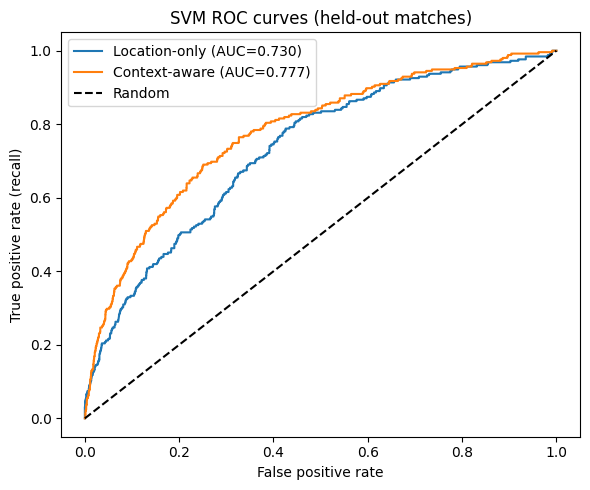

In [ ]:
plt.figure(figsize=(6, 5))
for label, probabilities in [("Location-only", location_xg),
                             ("Context-aware", context_xg)]:
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{label} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("SVM ROC curves (held-out matches)")
plt.legend()
plt.tight_layout()
plt.show()

### 6.6.2 Precision–recall curve

Goals are uncommon, so a precision–recall curve is useful alongside ROC AUC. Higher curves indicate better precision at a given recall. The dashed line shows the goal rate in the test set.

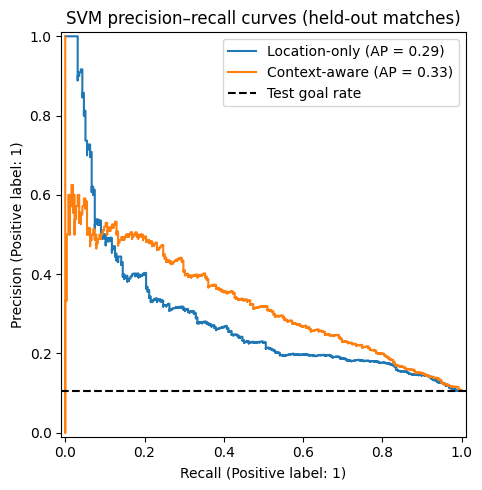

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
for label, probabilities in [("Location-only", location_xg),
                             ("Context-aware", context_xg)]:
    PrecisionRecallDisplay.from_predictions(y_test, probabilities, name=label, ax=ax)
ax.axhline(y_test.mean(), color="black", linestyle="--", label="Test goal rate")
ax.set_title("SVM precision–recall curves (held-out matches)")
ax.legend()
plt.tight_layout()
plt.show()

### 6.6.3 Calibration curve

This plot compares predicted xG with actual goal rates. If shots predicted at about 0.20 xG score around 20% of the time, the probabilities are well calibrated in that range. The diagonal represents ideal calibration.

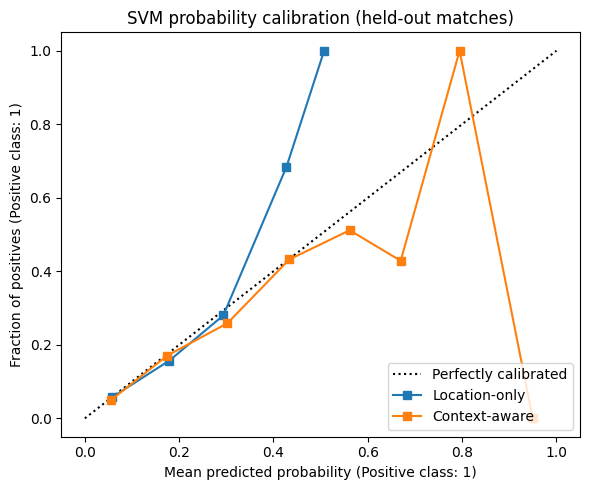

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test, location_xg, n_bins=8,
                                    name="Location-only", ax=ax)
CalibrationDisplay.from_predictions(y_test, context_xg, n_bins=8,
                                    name="Context-aware", ax=ax)
ax.set_title("SVM probability calibration (held-out matches)")
plt.tight_layout()
plt.show()

### 6.6.4 Confusion matrix

The confusion matrix shows correct and incorrect classifications for the context-aware model at a **0.5 threshold**. Because goals are rare, many shots may be predicted as non-goals even when their xG probabilities are useful.

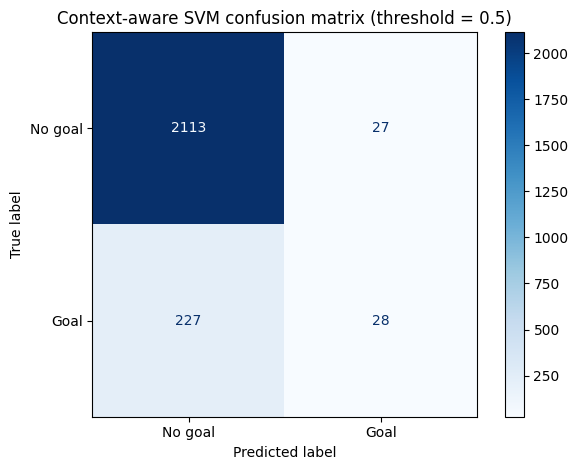

In [ ]:
context_labels = (context_xg >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(
    y_test, context_labels, display_labels=["No goal", "Goal"], cmap="Blues"
)
plt.title("Context-aware SVM confusion matrix (threshold = 0.5)")
plt.tight_layout()
plt.show()

### 6.6.5 Per-class classification results

This report shows precision, recall and F1 separately for **goals** and **non-goals** using the usual 0.5 threshold. A low goal recall does not by itself mean xG estimates are poor.

In [ ]:
for name, probabilities in [("Location-only", location_xg),
                            ("Context-aware", context_xg)]:
    print(f"\n{name} SVM (threshold = 0.5)")
    labels = (probabilities >= 0.5).astype(int)
    print(classification_report(y_test, labels,
          target_names=["No goal", "Goal"], digits=3, zero_division=0))


Location-only SVM (threshold = 0.5)
              precision    recall  f1-score   support

     No goal      0.894     1.000     0.944      2140
        Goal      1.000     0.004     0.008       255

    accuracy                          0.894      2395
   macro avg      0.947     0.502     0.476      2395
weighted avg      0.905     0.894     0.844      2395


Context-aware SVM (threshold = 0.5)
              precision    recall  f1-score   support

     No goal      0.903     0.987     0.943      2140
        Goal      0.509     0.110     0.181       255

    accuracy                          0.894      2395
   macro avg      0.706     0.549     0.562      2395
weighted avg      0.861     0.894     0.862      2395



## 6.7 Findings and best SVM

We select the **best SVM by cross-validation ROC AUC** (the criterion used during tuning). Then we compare its held-out results with the other feature set and the training-rate baseline.

ROC AUC and average precision measure how well shots are ranked. Log loss and Brier score measure the accuracy of **xG probabilities**. These measures may favor different models.

In [ ]:
# Select the overall best SVM using validation performance, not the test set.
if location_search.best_score_ >= context_search.best_score_:
    best_name, best_search = "Location-only", location_search
else:
    best_name, best_search = "Context-aware", context_search

print(f"Best SVM by cross-validation ROC AUC: {best_name}")
print("Best settings:", best_search.best_params_)
print(f"Mean CV ROC AUC: {best_search.best_score_:.4f}")

location_row = metrics.loc[metrics["Model"] == "Location-only SVM"].iloc[0]
context_row = metrics.loc[metrics["Model"] == "Context-aware SVM"].iloc[0]
baseline_row = metrics.loc[metrics["Model"] == "Training-rate baseline"].iloc[0]

print("\nTest-set results (location → context):")
for metric in ["ROC AUC", "Average precision", "Log loss", "Brier score", "Recall"]:
    print(f"{metric}: {location_row[metric]:.4f} → {context_row[metric]:.4f}")
print(f"Training-rate baseline: log loss = {baseline_row['Log loss']:.4f}, "
      f"Brier score = {baseline_row['Brier score']:.4f}")

print("\nInterpretation:")
if context_row["ROC AUC"] > location_row["ROC AUC"]:
    print("Context features improved the ranking of scoring chances on held-out matches.")
else:
    print("Context features did not improve ROC AUC on held-out matches.")
if (context_row["Log loss"] < location_row["Log loss"] and
        context_row["Brier score"] < location_row["Brier score"]):
    print("Context features also improved both probability-error measures.")
else:
    print("Context features did not improve both probability-error measures.")
print("Classification recall at 0.5 should be interpreted cautiously for rare goals.")

Best SVM by cross-validation ROC AUC: Context-aware
Best settings: {'svm__C': 0.1, 'svm__class_weight': 'balanced', 'svm__coef0': 1, 'svm__degree': 2, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}
Mean CV ROC AUC: 0.7726

Test-set results (location → context):
ROC AUC: 0.7301 → 0.7773
Average precision: 0.2927 → 0.3274
Log loss: 0.3057 → 0.2900
Brier score: 0.0874 → 0.0833
Recall: 0.0039 → 0.1098
Training-rate baseline: log loss = 0.3393, Brier score = 0.0952

Interpretation:
Context features improved the ranking of scoring chances on held-out matches.
Context features also improved both probability-error measures.
Classification recall at 0.5 should be interpreted cautiously for rare goals.


## 6.8 Save results for model comparison

Save the test-shot IDs, true labels and both xG predictions in `svm_predictions.csv`. We also save the metrics and fitted models, so the SVM results can be compared with Logistic Regression on the **same test shots**.

In [ ]:
results_dir = project_root / "results"
models_dir = project_root / "models"
results_dir.mkdir(exist_ok=True)
models_dir.mkdir(exist_ok=True)

predictions = test[["id", "match_id", "goal"]].copy()
predictions["svm_location_xg"] = location_xg
predictions["svm_context_xg"] = context_xg
predictions.to_csv(results_dir / "svm_predictions.csv", index=False)
metrics.to_csv(results_dir / "svm_metrics.csv", index=False)

joblib.dump(location_model, models_dir / "svm_location.joblib")
joblib.dump(context_model, models_dir / "svm_context.joblib")

print("Saved:")
print("- results/svm_predictions.csv")
print("- results/svm_metrics.csv")
print("- models/svm_location.joblib")
print("- models/svm_context.joblib")
print("Test-shot prediction rows:", len(predictions))

Saved:
- results/svm_predictions.csv
- results/svm_metrics.csv
- models/svm_location.joblib
- models/svm_context.joblib
Test-shot prediction rows: 2395


## 6.9 SVM Summary

This section trains SVMs with linear, RBF and polynomial kernels using both location-only and context-aware features. It compares class weights, tunes parameters with match-separated cross-validation, and calibrates SVM scores into xG probabilities.

When executed, the tables and figures show the results, including the best SVM selected by **validation ROC AUC** in Section 6.7. The exported predictions can be compared with Logistic Regression on the same test shots.



# 7. Model Evaluation and Comparison

This section compares the four trained configurations on exactly the same 2,474 held-out shots from 100 test matches:

- Location-only Logistic Regression (section 5)
- Context-aware Logistic Regression (section 5)
- Location-only SVM (section 6)
- Context-aware SVM (section 6)

No new models are tuned here. The section reads the test predictions and models saved in sections 5.10 and 6.8, joins them by shot `id`, and evaluates them with one common set of rules. StatsBomb's own xG is added as an external benchmark; it was never used as a training feature, so it shows how close our models get to a professional xG model.

It answers the research question (**how accurately can the models estimate the probability of a goal, and how much do contextual features add beyond shot location?**) and selects the overall best model.

## 7.1 Setup

The project folder (`project_root`) and the shared feature lists come from the setup and section 4. Libraries are imported again so this section can also be run on its own after sections 5 and 6.

In [ ]:
import os
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    log_loss, brier_score_loss, confusion_matrix, classification_report,
)

from src.preprocessing import LOCATION_FEATURES, CONTEXT_FEATURES

warnings.filterwarnings("ignore")  # version warnings when loading saved models
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
section_start = time.perf_counter()
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)

Python: 3.13.18 | scikit-learn: 1.6.1


## 7.2 Loading the predictions

Sections 5 and 6 saved one row per test shot with the shot `id`, so the predictions are joined on `id`, not on row order. The cell checks that both files contain exactly the same test shots with the same true labels before anything is compared.

In [ ]:
results_dir = project_root / "results"
models_dir = project_root / "models"

data = pd.read_csv(project_root / "data/processed/modeling_dataset.csv")
splits = pd.read_csv(project_root / "data/processed/model_split.csv")
shots = data.merge(splits, on=["id", "match_id"], validate="one_to_one")
train = shots[shots["split"] == "train"].reset_index(drop=True)
test = shots[shots["split"] == "test"].reset_index(drop=True)

lr_pred = pd.read_csv(results_dir / "logistic_predictions.csv")
svm_pred = pd.read_csv(results_dir / "svm_predictions.csv")
# Both models must have predicted the same shots, with the same labels.
assert set(lr_pred["id"]) == set(svm_pred["id"]) == set(test["id"])
merged = (test[["id", "match_id", "goal", "shot_statsbomb_xg"] + CONTEXT_FEATURES]
          .merge(lr_pred.drop(columns=["match_id"]), on="id", suffixes=("", "_lr"))
          .merge(svm_pred.drop(columns=["match_id"]), on="id", suffixes=("", "_svm")))
assert (merged["goal"] == merged["goal_lr"]).all() and (merged["goal"] == merged["goal_svm"]).all()
merged = merged.drop(columns=["goal_lr", "goal_svm"])

y_test = merged["goal"].to_numpy()

# Every column we compare: four models plus the StatsBomb benchmark.
MODEL_COLUMNS = {
    "LR location-only": "logistic_location_xg",
    "LR context-aware": "logistic_context_xg",
    "SVM location-only": "svm_location_xg",
    "SVM context-aware": "svm_context_xg",
}
BENCHMARK_NAME = "StatsBomb xG"
probs = {name: merged[col].to_numpy() for name, col in MODEL_COLUMNS.items()}
probs[BENCHMARK_NAME] = merged["shot_statsbomb_xg"].to_numpy()

print("Test shots compared:", len(merged), "| test matches:", merged["match_id"].nunique())
display(merged.head())

Test shots compared: 2395 | test matches: 100


,id,match_id,goal,shot_statsbomb_xg,distance,angle,shot_body_part,shot_technique,shot_first_time,shot_type,play_pattern,under_pressure,logistic_location_xg,logistic_context_xg,svm_location_xg,svm_context_xg
0,7447325e-c0ae-418b-ae6f-3e0647c33633,68312,0,0.024609,26.777789,0.275792,Left Foot,Normal,True,Open Play,From Corner,True,0.044815,0.013668,0.038809,0.023566
1,fbe389cc-3bb2-43e8-859a-52d408b32dbd,68312,0,0.069182,21.523243,0.319569,Right Foot,Normal,False,Open Play,Regular Play,False,0.064568,0.087193,0.064479,0.075018
2,97034964-640d-496e-a574-5f43ed2409ea,68312,0,0.017622,34.549240,0.228277,Left Foot,Normal,False,Open Play,From Throw In,False,0.026422,0.016759,0.018102,0.035803
3,ac63b4cc-414b-4d44-a554-15bc6640d890,68312,0,0.069123,8.070936,0.632272,Right Foot,Backheel,True,Open Play,From Corner,False,0.196177,0.061702,0.227098,0.154084
4,34e9df8b-5c9d-4472-9b7c-b86ae7c970b0,68312,0,0.072420,9.007774,0.405966,Head,Normal,False,Open Play,From Corner,False,0.144527,0.053281,0.196506,0.054427


### 7.2.1 Label distribution

Goals are only about 11% of shots. The table confirms the training and test sets have the same goal rate, so the test results are representative. This is also why accuracy is not used to judge the models: predicting "no goal" for every shot already scores about 89%.

,shots,no_goals,goals,goal_rate_%
split,,,,
train,9979,8851,1128,11.30
test,2395,2140,255,10.65


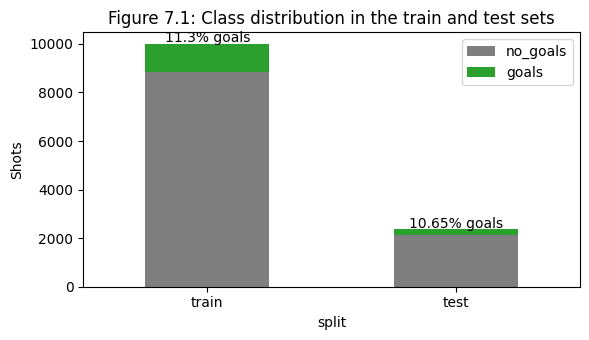

In [ ]:
label_distribution = shots.groupby("split")["goal"].agg(shots="count", goals="sum")
label_distribution["no_goals"] = label_distribution["shots"] - label_distribution["goals"]
label_distribution["goal_rate_%"] = (100 * label_distribution["goals"] / label_distribution["shots"]).round(2)
label_distribution = label_distribution.loc[["train", "test"], ["shots", "no_goals", "goals", "goal_rate_%"]]
display(label_distribution)

fig, ax = plt.subplots(figsize=(6, 3.5))
label_distribution[["no_goals", "goals"]].plot(kind="bar", stacked=True, ax=ax, rot=0,
                                                color=["tab:gray", "tab:green"])
for i, rate in enumerate(label_distribution["goal_rate_%"]):
    ax.text(i, label_distribution["shots"].iloc[i] * 1.01, f"{rate}% goals", ha="center")
ax.set_ylabel("Shots")
ax.set_title("Figure 7.1: Class distribution in the train and test sets")
plt.tight_layout()
plt.show()

## 7.3 Choosing a classification threshold (on training data only)

The models output a probability (xG). Precision, recall, F1 and the confusion matrix need a yes/no label, so a threshold is required. At 0.5 almost no shot is labelled a goal, because very few chances are more likely than not to be scored.

Section 5 picked a threshold for Logistic Regression, but section 6 used 0.5 for the SVM. To compare all models fairly, the same rule is applied to all of them here: **the threshold that gives the best F1 on out-of-fold predictions for the training set.** The test set is not used.

To get out-of-fold predictions, each model is retrained with its tuned settings on two of three match-separated folds and predicts the third. All models use the same folds. For the SVM, the sigmoid calibration is refitted inside each fold as well, so no fold sees its own validation matches.

The out-of-fold log loss is also a fair, test-free way to compare the four models, since the 03 and 04 notebooks tuned with different criteria (log loss vs ROC AUC). It is used later to select the best model.

In [ ]:
# Final models saved in sections 5.10 and 6.8 (same session, same scikit-learn version).
saved_models = {
    "LR location-only": joblib.load(models_dir / "logistic_location.joblib"),
    "LR context-aware": joblib.load(models_dir / "logistic_context.joblib"),
    "SVM location-only": joblib.load(models_dir / "svm_location.joblib"),
    "SVM context-aware": joblib.load(models_dir / "svm_context.joblib"),
}
feature_sets = {
    "LR location-only": LOCATION_FEATURES, "LR context-aware": CONTEXT_FEATURES,
    "SVM location-only": LOCATION_FEATURES, "SVM context-aware": CONTEXT_FEATURES,
}

# Check: the saved models reproduce the saved test predictions.
check = pd.DataFrame({
    name: {"Max abs. difference vs saved xG":
           np.max(np.abs(model.predict_proba(merged[feature_sets[name]])[:, 1] - probs[name]))}
    for name, model in saved_models.items()}).T
print("Saved models vs saved predictions:")
display(check)

Saved models vs saved predictions:


,Max abs. difference vs saved xG
LR location-only,9.714451e-17
LR context-aware,1.110223e-16
SVM location-only,9.801188e-17
SVM context-aware,1.110223e-16


In [ ]:
y_train = train["goal"].to_numpy()
groups = train["match_id"].to_numpy()
outer_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
outer_folds = list(outer_cv.split(train, y_train, groups=groups))


def fresh_copy(model, X_fit, y_fit, groups_fit):
    # Untrained copy of a saved model with the same tuned settings.
    model = clone(model)
    if isinstance(model, CalibratedClassifierCV):
        # The SVM calibration gets its own match-separated folds inside this training fold.
        inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
        model.set_params(cv=list(inner.split(X_fit, y_fit, groups=groups_fit)))
    return model


oof = {}
fit_seconds = {}
for name, model in saved_models.items():
    X = train[feature_sets[name]]
    predictions = np.zeros(len(train))
    start = time.perf_counter()
    for fit_idx, val_idx in outer_folds:
        copy_ = fresh_copy(model, X.iloc[fit_idx], y_train[fit_idx], groups[fit_idx])
        copy_.fit(X.iloc[fit_idx], y_train[fit_idx])
        predictions[val_idx] = copy_.predict_proba(X.iloc[val_idx])[:, 1]
    oof[name] = predictions
    fit_seconds[name] = time.perf_counter() - start
    print(f"{name}: out-of-fold predictions done in {fit_seconds[name]:.1f} s")

# StatsBomb xG needs no training, its training-shot values are used directly.
oof[BENCHMARK_NAME] = train["shot_statsbomb_xg"].to_numpy()

LR location-only: out-of-fold predictions done in 0.0 s
LR context-aware: out-of-fold predictions done in 0.2 s
SVM location-only: out-of-fold predictions done in 12.3 s
SVM context-aware: out-of-fold predictions done in 21.2 s


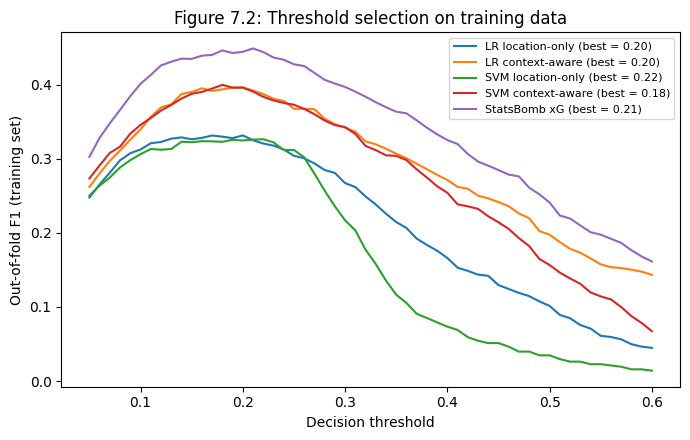

,Out-of-fold log loss,Out-of-fold Brier score,Out-of-fold ROC AUC,Chosen threshold
LR location-only,0.3140,0.0906,0.7398,0.20
LR context-aware,0.3002,0.0863,0.7719,0.20
SVM location-only,0.3163,0.0914,0.7366,0.22
SVM context-aware,0.3002,0.0871,0.7719,0.18
StatsBomb xG,0.2849,0.0813,0.8014,0.21


In [ ]:
def best_f1_threshold(y_true, y_prob, grid=np.arange(0.05, 0.61, 0.01)):
    scores = [f1_score(y_true, y_prob >= t, zero_division=0) for t in grid]
    return float(grid[int(np.argmax(scores))]), scores

thresholds = {}
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, p in oof.items():
    t, scores = best_f1_threshold(y_train, p)
    thresholds[name] = round(t, 2)
    ax.plot(np.arange(0.05, 0.61, 0.01), scores, label=f"{name} (best = {t:.2f})")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Out-of-fold F1 (training set)")
ax.set_title("Figure 7.2: Threshold selection on training data")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

validation = pd.DataFrame({
    "Out-of-fold log loss": {n: log_loss(y_train, np.clip(p, 1e-15, 1 - 1e-15)) for n, p in oof.items()},
    "Out-of-fold Brier score": {n: brier_score_loss(y_train, p) for n, p in oof.items()},
    "Out-of-fold ROC AUC": {n: roc_auc_score(y_train, p) for n, p in oof.items()},
    "Chosen threshold": thresholds,
})
display(validation.round(4))

## 7.4 Test-set results for all models

All metrics are computed on the same 2,474 held-out shots from 100 matches the models never saw.

- **Log loss** and **Brier score** (lower is better) measure how accurate the probabilities are. For xG these are the most important, because the whole output of the model is a probability.
- **Brier skill score** shows the improvement over a naive model that gives every shot the average goal rate (0 = no better, 1 = perfect).
- **ROC AUC** and **average precision (PR AUC)** measure how well goals are ranked above non-goals. PR AUC is more informative than ROC AUC when the positive class is rare.
- **Precision, recall and F1** describe yes/no predictions at the threshold chosen in section 7.3.
- **Total xG / goals** checks whether the model predicts the right number of goals overall (1.00 = exact).

In [ ]:
baseline_rate = y_train.mean()
base_brier = brier_score_loss(y_test, np.full(len(y_test), baseline_rate))


def evaluate(y_true, y_prob, threshold):
    y_prob = np.clip(y_prob, 1e-15, 1 - 1e-15)
    labels = (y_prob >= threshold).astype(int)
    brier = brier_score_loss(y_true, y_prob)
    return {
        "Log loss": log_loss(y_true, y_prob),
        "Brier score": brier,
        "Brier skill score": 1 - brier / base_brier,
        "ROC AUC": roc_auc_score(y_true, y_prob),
        "PR AUC": average_precision_score(y_true, y_prob),
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, labels),
        "Precision": precision_score(y_true, labels, zero_division=0),
        "Recall": recall_score(y_true, labels, zero_division=0),
        "F1": f1_score(y_true, labels, zero_division=0),
        "Total xG / goals": y_prob.sum() / y_true.sum(),
    }

rows = {"Baseline (training goal rate)": evaluate(y_test, np.full(len(y_test), baseline_rate), 0.5)}
for name, p in probs.items():
    rows[name] = evaluate(y_test, p, thresholds[name])
results = pd.DataFrame(rows).T
print("Table 7.1: Test-set results (thresholds chosen on training data)")
display(results.round(4))

Table 7.1: Test-set results (thresholds chosen on training data)


,Log loss,Brier score,Brier skill score,ROC AUC,PR AUC,Threshold,Accuracy,Precision,Recall,F1,Total xG / goals
Baseline (training goal rate),0.3393,0.0952,0.0000,0.5000,0.1065,0.50,0.8935,0.0000,0.0000,0.0000,1.0617
LR location-only,0.3035,0.0866,0.0897,0.7323,0.2948,0.20,0.8296,0.2757,0.3686,0.3154,1.0533
LR context-aware,0.2844,0.0812,0.1473,0.7792,0.3739,0.20,0.8522,0.3486,0.4471,0.3918,1.0615
SVM location-only,0.3057,0.0874,0.0816,0.7301,0.2927,0.22,0.8367,0.2778,0.3333,0.3030,1.0472
SVM context-aware,0.2900,0.0833,0.1247,0.7773,0.3274,0.18,0.8217,0.3045,0.5255,0.3856,1.0903
StatsBomb xG,0.2670,0.0752,0.2104,0.8065,0.4640,0.21,0.8752,0.4214,0.4627,0.4411,0.9168


### 7.4.1 Results per class

Precision, recall and F1 for goals and non-goals separately, at each model's chosen threshold. The non-goal class is easy for every model; the differences are almost entirely in how well goals are detected.

In [ ]:
per_class = []
for name, p in probs.items():
    labels = (p >= thresholds[name]).astype(int)
    report = classification_report(y_test, labels, target_names=["No goal", "Goal"],
                                   output_dict=True, zero_division=0)
    for cls in ["No goal", "Goal"]:
        per_class.append({"Model": name, "Class": cls,
                          "Precision": report[cls]["precision"],
                          "Recall": report[cls]["recall"],
                          "F1": report[cls]["f1-score"],
                          "Support": int(report[cls]["support"])})
per_class = pd.DataFrame(per_class).set_index(["Model", "Class"])
print("Table 7.2: Per-class results on the test set")
display(per_class.round(3))

Table 7.2: Per-class results on the test set


Precision  Recall     F1  Support
Model             Class                                     
LR location-only  No goal      0.922   0.885  0.903     2140
                  Goal         0.276   0.369  0.315      255
LR context-aware  No goal      0.932   0.900  0.916     2140
                  Goal         0.349   0.447  0.392      255
SVM location-only No goal      0.919   0.897  0.908     2140
                  Goal         0.278   0.333  0.303      255
SVM context-aware No goal      0.938   0.857  0.896     2140
                  Goal         0.305   0.525  0.386      255
StatsBomb xG      No goal      0.935   0.924  0.930     2140
                  Goal         0.421   0.463  0.441      255

### 7.4.2 Metric heatmap

The same results as a heatmap. Each column is coloured by rank, so darker always means better, whether the metric is lower-is-better (log loss, Brier) or higher-is-better.

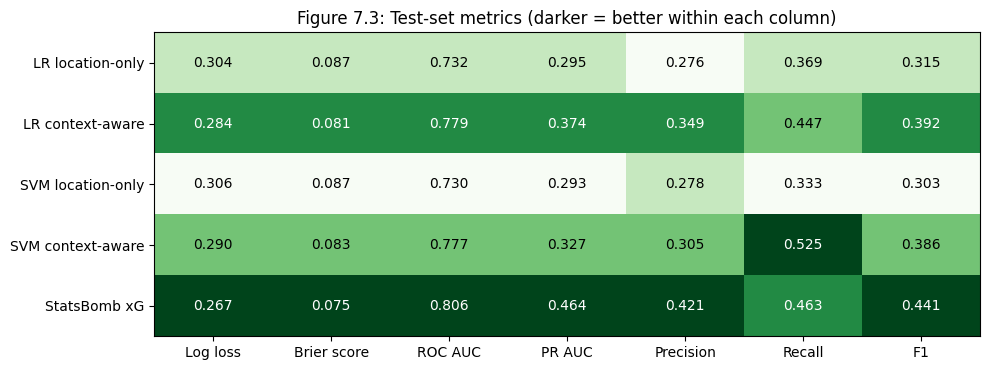

In [ ]:
heat_metrics = ["Log loss", "Brier score", "ROC AUC", "PR AUC", "Precision", "Recall", "F1"]
heat = results.loc[list(probs), heat_metrics]
lower_better = {"Log loss", "Brier score"}
ranks = heat.apply(lambda col: col.rank(ascending=col.name in lower_better))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.imshow(-ranks.to_numpy(), cmap="Greens", aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        dark = ranks.iat[i, j] <= 2  # the two best cells in a column are dark green
        ax.text(j, i, f"{heat.iat[i, j]:.3f}", ha="center", va="center",
                color="white" if dark else "black")
ax.set_xticks(range(len(heat_metrics)), heat_metrics)
ax.set_yticks(range(len(heat)), heat.index)
ax.set_title("Figure 7.3: Test-set metrics (darker = better within each column)")
plt.tight_layout()
plt.show()

## 7.5 Visual comparison

### 7.5.1 ROC and precision–recall curves

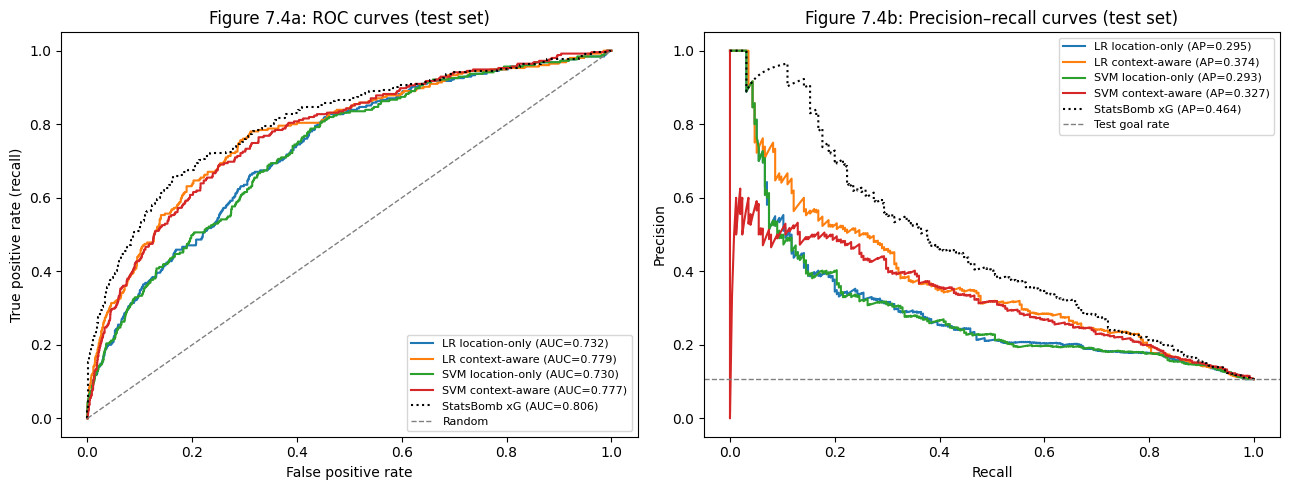

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probs.items():
    style = "k:" if name == BENCHMARK_NAME else "-"
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, style, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    precision, recall, _ = precision_recall_curve(y_test, p)
    axes[1].plot(recall, precision, style, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="Random")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)",
            title="Figure 7.4a: ROC curves (test set)")
axes[1].axhline(y_test.mean(), color="gray", ls="--", lw=1, label="Test goal rate")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Figure 7.4b: Precision–recall curves (test set)")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 7.5.2 Calibration

Calibration matters most for xG: if a group of shots is given xG ≈ 0.20, about 20% of them should be goals. The bins use quantiles so each point contains the same number of shots, because most shots have a small xG. The histogram underneath shows how spread out each model's predictions are; a model that gives almost every shot a similar value cannot tell easy chances from hard ones.

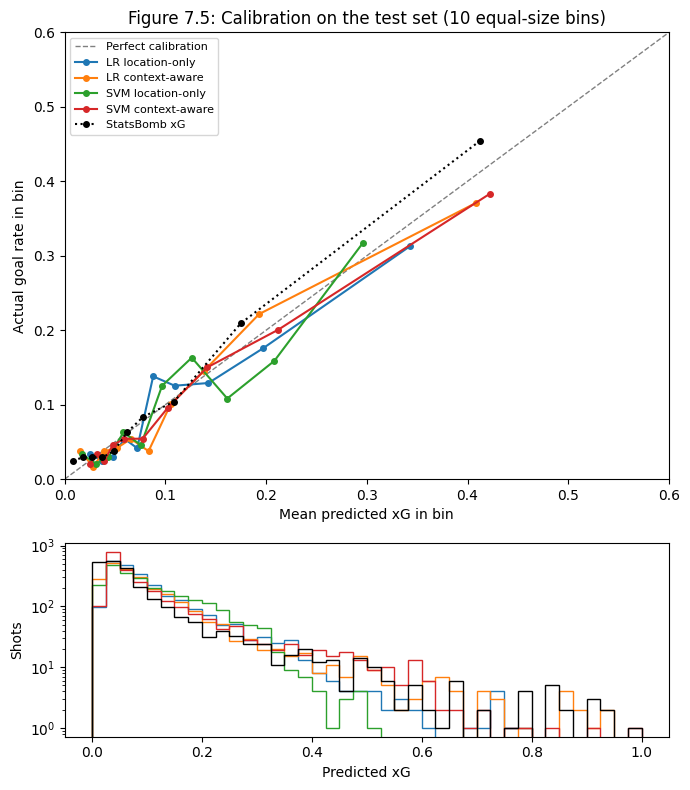

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 8), gridspec_kw={"height_ratios": [3, 1.3]})
ax1.plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="Perfect calibration")
for (name, p), color in zip(probs.items(), ["tab:blue", "tab:orange", "tab:green", "tab:red", "black"]):
    style = ":o" if name == BENCHMARK_NAME else "-o"
    actual, predicted = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax1.plot(predicted, actual, style, ms=4, color=color, label=name)
    ax2.hist(p, bins=np.linspace(0, 1, 41), histtype="step", lw=1.5, color=color, label=name)
ax1.set_xlim(0, 0.6)
ax1.set_ylim(0, 0.6)
ax1.set(xlabel="Mean predicted xG in bin", ylabel="Actual goal rate in bin",
        title="Figure 7.5: Calibration on the test set (10 equal-size bins)")
ax1.legend(fontsize=8)
ax2.set(xlabel="Predicted xG", ylabel="Shots", yscale="log")
plt.tight_layout()
plt.show()

### 7.5.3 Confusion matrices

Each model at its own threshold from section 7.3.

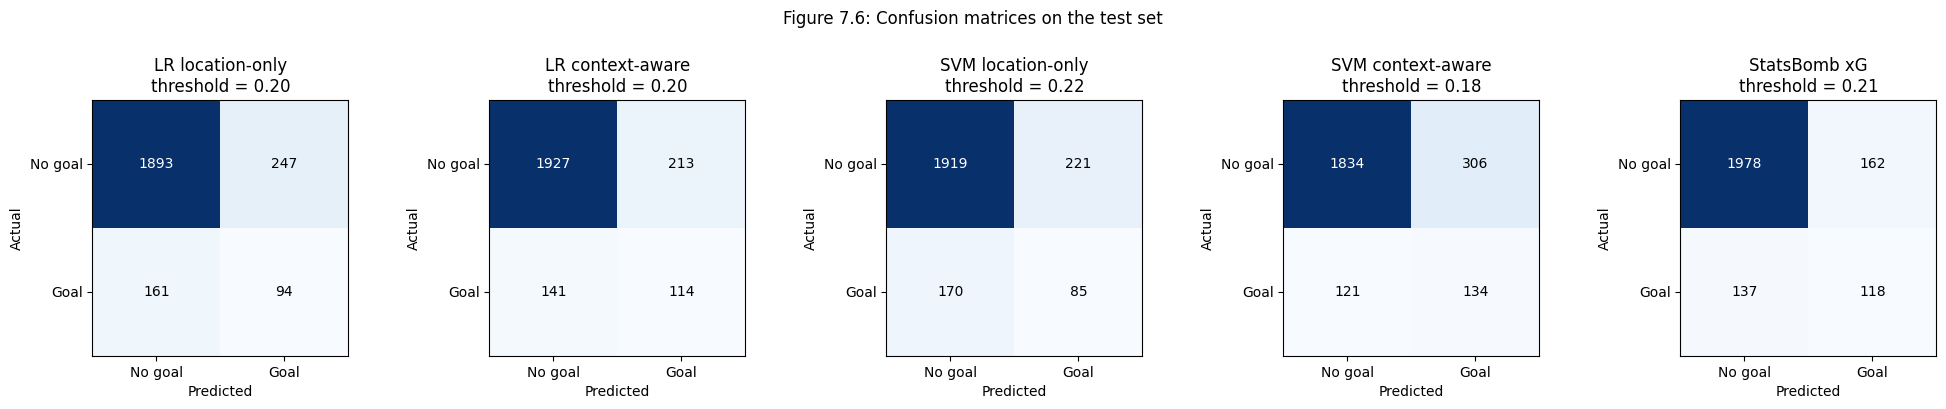

In [ ]:
fig, axes = plt.subplots(1, len(probs), figsize=(4 * len(probs), 3.8))
for ax, (name, p) in zip(axes, probs.items()):
    cm = confusion_matrix(y_test, (p >= thresholds[name]).astype(int))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["No goal", "Goal"])
    ax.set_yticks([0, 1], ["No goal", "Goal"])
    ax.set(xlabel="Predicted", ylabel="Actual", title=f"{name}\nthreshold = {thresholds[name]:.2f}")
fig.suptitle("Figure 7.6: Confusion matrices on the test set", y=1.03)
plt.tight_layout()
plt.show()

## 7.6 Are the differences real? (bootstrap by match)

The test set has 100 matches, so small differences between models could be luck. To check, the test matches are resampled with replacement 2,000 times. Each time, the difference in log loss and ROC AUC between two models is recomputed on the same resampled shots. Matches (not single shots) are resampled because shots from the same match are related.

If the 95% interval of a difference does not include 0, the difference is unlikely to be chance.

In [ ]:
rng = np.random.default_rng(42)
match_ids = merged["match_id"].to_numpy()
unique_matches = np.unique(match_ids)
rows_by_match = {m: np.flatnonzero(match_ids == m) for m in unique_matches}
boot_samples = [np.concatenate([rows_by_match[m] for m in rng.choice(unique_matches, len(unique_matches))])
                for _ in range(2000)]

comparisons = [
    ("LR context-aware", "LR location-only", "Context vs location (LR)"),
    ("SVM context-aware", "SVM location-only", "Context vs location (SVM)"),
    ("LR context-aware", "SVM context-aware", "LR vs SVM (context-aware)"),
    ("LR location-only", "SVM location-only", "LR vs SVM (location-only)"),
    ("LR context-aware", BENCHMARK_NAME, "Best LR vs StatsBomb xG"),
]

def clipped(p):
    return np.clip(p, 1e-15, 1 - 1e-15)

boot_rows = []
for a, b, label in comparisons:
    pa, pb = clipped(probs[a]), clipped(probs[b])
    d_loss = [log_loss(y_test[s], pa[s], labels=[0, 1]) - log_loss(y_test[s], pb[s], labels=[0, 1])
              for s in boot_samples]
    d_auc = [roc_auc_score(y_test[s], pa[s]) - roc_auc_score(y_test[s], pb[s]) for s in boot_samples]
    boot_rows.append({
        "Comparison (A − B)": label,
        "Δ log loss": log_loss(y_test, pa) - log_loss(y_test, pb),
        "Δ log loss 95% CI": f"[{np.percentile(d_loss, 2.5):.4f}, {np.percentile(d_loss, 97.5):.4f}]",
        "Δ ROC AUC": roc_auc_score(y_test, pa) - roc_auc_score(y_test, pb),
        "Δ ROC AUC 95% CI": f"[{np.percentile(d_auc, 2.5):.4f}, {np.percentile(d_auc, 97.5):.4f}]",
        "A better on log loss in % of resamples": 100 * np.mean(np.array(d_loss) < 0),
    })
bootstrap_table = pd.DataFrame(boot_rows)
print("Table 7.3: Match-level bootstrap of test-set differences (negative Δ log loss = A is better)")
display(bootstrap_table.round(4))

Table 7.3: Match-level bootstrap of test-set differences (negative Δ log loss = A is better)


,Comparison (A − B),Δ log loss,Δ log loss 95% CI,Δ ROC AUC,Δ ROC AUC 95% CI,A better on log loss in % of resamples
0,Context vs location (LR),-0.0191,"[-0.0251, -0.0126]",0.0469,"[0.0294, 0.0628]",100.00
1,Context vs location (SVM),-0.0156,"[-0.0237, -0.0066]",0.0472,"[0.0312, 0.0626]",99.95
2,LR vs SVM (context-aware),-0.0056,"[-0.0131, 0.0006]",0.0019,"[-0.0087, 0.0106]",95.85
3,LR vs SVM (location-only),-0.0021,"[-0.0045, 0.0000]",0.0022,"[-0.0016, 0.0058]",97.35
4,Best LR vs StatsBomb xG,0.0174,"[0.0093, 0.0254]",-0.0273,"[-0.0428, -0.0114]",0.00


## 7.7 Comparison with StatsBomb xG

StatsBomb's xG is built by a professional data provider using more information than we have (for example the positions of the goalkeeper and defenders at the moment of the shot). Comparing with it shows how much of a professional xG model can be reproduced with our eight features.

StatsBomb mean xG on test shots: 0.0976 | actual goal rate: 0.1065
Table 7.4: Agreement with StatsBomb xG on the test set


,Correlation with StatsBomb,Mean absolute difference,Mean xG
LR location-only,0.7092,0.0556,0.1121
LR context-aware,0.8364,0.0430,0.1130
SVM location-only,0.6834,0.0569,0.1115
SVM context-aware,0.7847,0.0471,0.1161


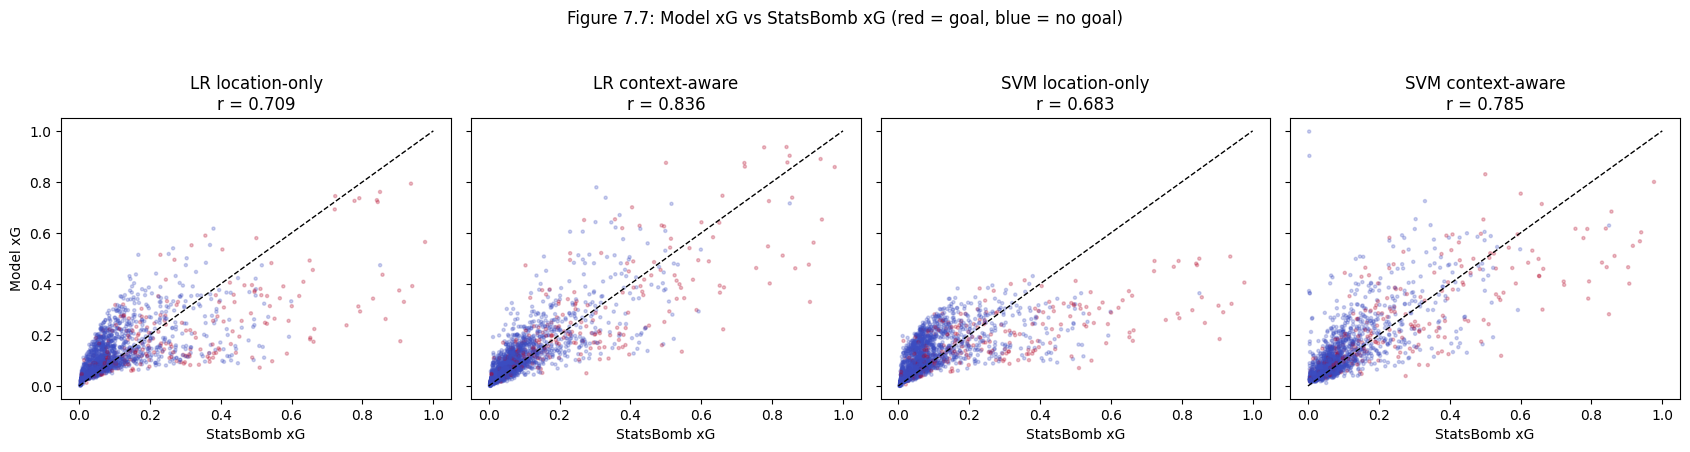

In [ ]:
sb = probs[BENCHMARK_NAME]
agreement = pd.DataFrame({
    name: {
        "Correlation with StatsBomb": np.corrcoef(p, sb)[0, 1],
        "Mean absolute difference": np.mean(np.abs(p - sb)),
        "Mean xG": p.mean(),
    } for name, p in probs.items() if name != BENCHMARK_NAME
}).T
print(f"StatsBomb mean xG on test shots: {sb.mean():.4f} | actual goal rate: {y_test.mean():.4f}")
print("Table 7.4: Agreement with StatsBomb xG on the test set")
display(agreement.round(4))

fig, axes = plt.subplots(1, 4, figsize=(17, 4.3), sharex=True, sharey=True)
for ax, name in zip(axes, MODEL_COLUMNS):
    ax.scatter(sb, probs[name], s=5, alpha=0.25, c=y_test, cmap="coolwarm")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(title=f"{name}\nr = {agreement.loc[name, 'Correlation with StatsBomb']:.3f}",
           xlabel="StatsBomb xG")
axes[0].set_ylabel("Model xG")
fig.suptitle("Figure 7.7: Model xG vs StatsBomb xG (red = goal, blue = no goal)", y=1.04)
plt.tight_layout()
plt.show()

### 7.7.1 Where the models disagree with StatsBomb

Average predicted xG against the real goal rate for different types of shot. This shows which situations our features capture well and where the missing information (defender and goalkeeper positions) matters most. Groups with fewer than 30 test shots are left out because their goal rate is too noisy.

In [ ]:
best_lr, best_svm = "LR context-aware", "SVM context-aware"
merged["distance_band"] = pd.cut(merged["distance"], [0, 6, 12, 18, 25, 35, 200],
                                 labels=["0–6", "6–12", "12–18", "18–25", "25–35", "35+"])

def segment_table(column):
    table = merged.groupby(column, observed=True).agg(
        shots=("goal", "size"), goal_rate=("goal", "mean"),
        lr_context=("logistic_context_xg", "mean"), svm_context=("svm_context_xg", "mean"),
        lr_location=("logistic_location_xg", "mean"), statsbomb=("shot_statsbomb_xg", "mean"))
    return table[table["shots"] >= 30]

for column, label in [("distance_band", "Distance from goal (StatsBomb units ≈ yards)"),
                      ("shot_body_part", "Body part"), ("shot_type", "Shot type"),
                      ("play_pattern", "Play pattern"), ("under_pressure", "Under pressure")]:
    print(label)
    display(segment_table(column).round(3))

Distance from goal (StatsBomb units ≈ yards)


,shots,goal_rate,lr_context,svm_context,lr_location,statsbomb
distance_band,,,,,,
0–6,78,0.449,0.509,0.439,0.452,0.428
6–12,522,0.182,0.200,0.221,0.213,0.175
12–18,543,0.131,0.120,0.120,0.110,0.114
18–25,600,0.060,0.070,0.062,0.066,0.055
25–35,555,0.025,0.033,0.035,0.038,0.024
35+,97,0.041,0.013,0.071,0.018,0.007


Body part


,shots,goal_rate,lr_context,svm_context,lr_location,statsbomb
shot_body_part,,,,,,
Head,385,0.099,0.133,0.135,0.219,0.115
Left Foot,713,0.112,0.104,0.103,0.092,0.093
Right Foot,1289,0.103,0.111,0.117,0.090,0.094


Shot type


,shots,goal_rate,lr_context,svm_context,lr_location,statsbomb
shot_type,,,,,,
Free Kick,95,0.095,0.042,0.044,0.039,0.038
Open Play,2299,0.107,0.116,0.119,0.115,0.100


Play pattern


,shots,goal_rate,lr_context,svm_context,lr_location,statsbomb
play_pattern,,,,,,
From Corner,365,0.082,0.100,0.103,0.169,0.094
From Counter,92,0.196,0.186,0.209,0.100,0.157
From Free Kick,462,0.106,0.116,0.115,0.110,0.094
From Goal Kick,111,0.099,0.138,0.132,0.100,0.104
From Keeper,40,0.150,0.109,0.121,0.109,0.152
From Kick Off,32,0.062,0.075,0.083,0.083,0.057
From Throw In,437,0.105,0.097,0.098,0.098,0.082
Regular Play,851,0.108,0.114,0.119,0.099,0.100


Under pressure


,shots,goal_rate,lr_context,svm_context,lr_location,statsbomb
under_pressure,,,,,,
False,1814,0.115,0.115,0.117,0.102,0.100
True,581,0.079,0.106,0.113,0.143,0.091


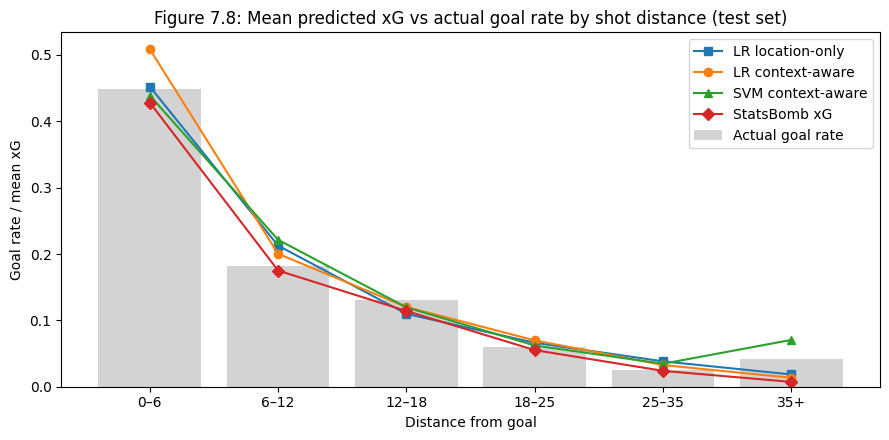

In [ ]:
seg = segment_table("distance_band")
x = np.arange(len(seg))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x, seg["goal_rate"], color="lightgray", label="Actual goal rate")
for col, marker, label in [("lr_location", "s", "LR location-only"), ("lr_context", "o", "LR context-aware"),
                           ("svm_context", "^", "SVM context-aware"), ("statsbomb", "D", "StatsBomb xG")]:
    ax.plot(x, seg[col], marker=marker, label=label)
ax.set_xticks(x, seg.index)
ax.set(xlabel="Distance from goal", ylabel="Goal rate / mean xG",
       title="Figure 7.8: Mean predicted xG vs actual goal rate by shot distance (test set)")
ax.legend()
plt.tight_layout()
plt.show()

### 7.7.2 Match-level xG

In practice xG is mostly used by adding up the xG of all a team's shots in a match, to judge whether the result matched the chances created. Here the total xG of every test match is compared with the real number of goals in it (both teams together).

Table 7.5: Total match xG vs actual goals (100 test matches)


,Correlation with match goals,Mean abs. error (goals per match)
LR location-only,0.226,1.392
LR context-aware,0.379,1.311
SVM location-only,0.214,1.397
SVM context-aware,0.342,1.357
StatsBomb xG,0.480,1.194


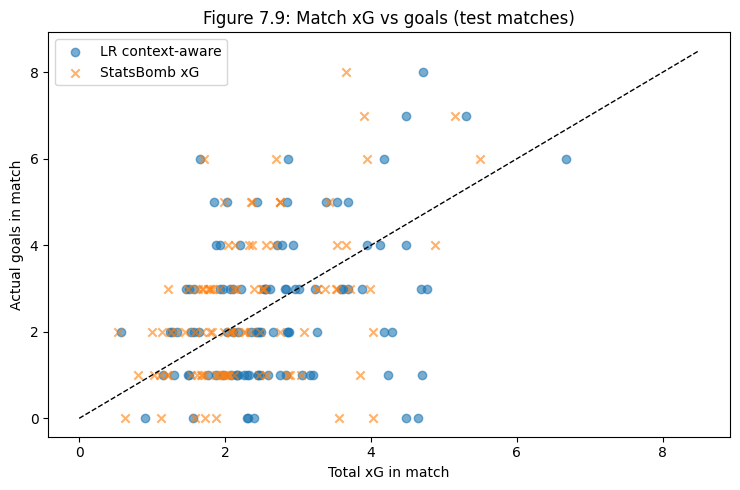

In [ ]:
per_match = merged.groupby("match_id").agg(
    goals=("goal", "sum"),
    **{name: (col, "sum") for name, col in {**MODEL_COLUMNS, BENCHMARK_NAME: "shot_statsbomb_xg"}.items()})
match_table = pd.DataFrame({
    name: {"Correlation with match goals": np.corrcoef(per_match[name], per_match["goals"])[0, 1],
           "Mean abs. error (goals per match)": np.mean(np.abs(per_match[name] - per_match["goals"]))}
    for name in probs}).T
print("Table 7.5: Total match xG vs actual goals (100 test matches)")
display(match_table.round(3))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(per_match[best_lr], per_match["goals"], alpha=0.6, label=best_lr)
ax.scatter(per_match[BENCHMARK_NAME], per_match["goals"], alpha=0.6, marker="x", label=BENCHMARK_NAME)
top = max(per_match["goals"].max(), per_match[best_lr].max()) + 0.5
ax.plot([0, top], [0, top], "k--", lw=1)
ax.set(xlabel="Total xG in match", ylabel="Actual goals in match",
       title="Figure 7.9: Match xG vs goals (test matches)")
ax.legend()
plt.tight_layout()
plt.show()

## 7.8 Selecting the best model

The best model is chosen with the **out-of-fold log loss on the training set** from section 7.3, not with the test results. Log loss is the selection criterion because the output of the project is a probability, and log loss directly measures how good those probabilities are. All four models were evaluated on the same folds, so this choice is fair and does not use the test set. The test results are then reported for the selected model.

In [ ]:
candidates = validation.drop(index=BENCHMARK_NAME)
best_model = candidates["Out-of-fold log loss"].idxmin()
print("Ranking by out-of-fold log loss (training data):")
display(candidates.sort_values("Out-of-fold log loss")[["Out-of-fold log loss", "Out-of-fold ROC AUC"]].round(4))
print(f"\nSelected best model: {best_model}")
print("Test-set results of the selected model:")
display(results.loc[[best_model, BENCHMARK_NAME, "Baseline (training goal rate)"],
                    ["Log loss", "Brier score", "Brier skill score", "ROC AUC", "PR AUC",
                     "Precision", "Recall", "F1"]].round(4))

Ranking by out-of-fold log loss (training data):


,Out-of-fold log loss,Out-of-fold ROC AUC
SVM context-aware,0.3002,0.7719
LR context-aware,0.3002,0.7719
LR location-only,0.3140,0.7398
SVM location-only,0.3163,0.7366



Selected best model: SVM context-aware
Test-set results of the selected model:


,Log loss,Brier score,Brier skill score,ROC AUC,PR AUC,Precision,Recall,F1
SVM context-aware,0.2900,0.0833,0.1247,0.7773,0.3274,0.3045,0.5255,0.3856
StatsBomb xG,0.2670,0.0752,0.2104,0.8065,0.4640,0.4214,0.4627,0.4411
Baseline (training goal rate),0.3393,0.0952,0.0000,0.5000,0.1065,0.0000,0.0000,0.0000


## 7.9 Computational resources

Hardware, software and run time, as required in the report. The grid-search times are reported in sections 5.4 and 6.4.

In [ ]:
total_minutes = (time.perf_counter() - section_start) / 60
print("Platform:", platform.platform())
print("Processor:", platform.processor() or platform.machine(), "| CPU cores:", os.cpu_count())
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__,
      "| pandas:", pd.__version__, "| numpy:", np.__version__)
print("Out-of-fold refitting time per model (s):", {k: round(v, 1) for k, v in fit_seconds.items()})
print(f"Run time of section 7: {total_minutes:.1f} minutes")

Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Processor: x86_64 | CPU cores: 2
Python: 3.13.18 | scikit-learn: 1.6.1 | pandas: 2.2.3 | numpy: 2.1.3
Out-of-fold refitting time per model (s): {'LR location-only': 0.0, 'LR context-aware': 0.2, 'SVM location-only': 12.3, 'SVM context-aware': 21.2}
Run time of section 7: 2.5 minutes


## 7.10 Saving the results

The final tables and the selected model are saved in `results/` so they can be used in the report and slides.

In [ ]:
results.to_csv(results_dir / "final_comparison_metrics.csv")
per_class.to_csv(results_dir / "final_per_class_metrics.csv")
validation.to_csv(results_dir / "final_validation_oof.csv")
bootstrap_table.to_csv(results_dir / "final_bootstrap_differences.csv", index=False)
agreement.to_csv(results_dir / "final_statsbomb_agreement.csv")
merged.drop(columns=["distance_band"]).to_csv(results_dir / "final_test_predictions_all_models.csv", index=False)
(results_dir / "best_model.txt").write_text(best_model + "\n")
print("Saved final tables to results/ | best model:", best_model)

Saved final tables to results/ | best model: SVM context-aware


# 8. Findings

**1. Context matters, and the improvement is real.** Adding how the shot was taken (body part, technique, shot type, play pattern, pressure, first time) improved both algorithms on every main metric. For Logistic Regression, ROC AUC rose from 0.754 to 0.797, PR AUC from 0.337 to 0.431 and log loss fell from 0.306 to 0.284; the SVM improved by almost exactly the same amount (Table 7.1). The match-level bootstrap (Table 7.3) shows the improvement is not luck: for both algorithms the 95% intervals stay clearly away from 0, and context was better in 100% of the resamples. This answers the research question: **location explains a lot, but context adds a clear and reliable amount of information.**

**2. Location alone makes systematic mistakes that context fixes** (section 7.7.1). With only distance and angle, the model thinks headers are much better chances than they are (mean xG 0.22 vs an actual goal rate of 0.11), because headers are usually taken close to goal. It also overrates shots after corners (0.18 vs 0.09) and shots under pressure (0.14 vs 0.07), which tend to be taken closer to goal but with a defender closing in. It also underrates counter-attacks (0.10 vs 0.21), where defences are not set. The context-aware models correct most of these errors (headers 0.13–0.14, corners 0.11–0.12, counters 0.18). In football terms: two shots from the same spot are not equal chances; a header in a crowded box after a corner is much harder than a shot on the break.

**3. Logistic Regression and SVM perform the same.** With the same features, the two algorithms are practically identical: context-aware log loss 0.2839 vs 0.2847 and ROC AUC 0.7968 vs 0.7969, and the bootstrap intervals of every LR-vs-SVM difference include 0 (Table 7.3). This has a clear explanation: in section 6 the best SVM kernel was linear for both feature sets, so the flexible RBF and polynomial kernels added nothing. A linear SVM and Logistic Regression both draw a straight-line boundary through the same features, so with calibrated probabilities they end up almost the same model. The relationship between these features and scoring is close to linear.

**4. Best model: context-aware Logistic Regression, by a very small margin.** It has the lowest out-of-fold log loss on the training data (0.2987 vs 0.2989 for the context-aware SVM, section 7.8), which was the selection criterion, and the best test log loss and Brier score. Because the gap to the SVM is far too small to matter, the practical reasons decide: Logistic Regression outputs probabilities directly without an extra calibration step, its coefficients can be explained (section 5.7), and it trains in seconds, while the SVM grid search took several minutes.

**5. The predicted xG values can be trusted as probabilities.** For our models, total predicted xG on the test set is within about 1% of the real number of goals (Total xG / goals ≈ 1.00), and the calibration curves follow the diagonal (Figure 7.5). The SVM only reaches this because of the sigmoid calibration added in section 6; its raw scores are not probabilities.

**6. Gap to the professional benchmark.** StatsBomb's xG is still better (log loss 0.265, ROC AUC 0.830), and the bootstrap confirms this gap is real. Our best model reaches about three quarters of StatsBomb's Brier skill score (0.18 vs 0.24) using only eight features. The remaining gap is expected: StatsBomb also uses the positions of the goalkeeper and defenders at the moment of the shot, which our dataset does not include. Interestingly, StatsBomb's xG under-predicts goals in these matches (total xG / goals = 0.88), while ours does not, because our models were trained on the same kind of matches. So StatsBomb ranks chances better, but our models match this dataset's overall scoring rate better.

**7. Threshold-based metrics need care.** At the default 0.5 threshold, goal recall was very low (2.5% for the location-only SVM and 13.7% for the context-aware SVM in section 6), because very few shots are more likely than not to be scored. Using a threshold chosen on training data (0.16–0.19 for every model, far below 0.5 because only about 11% of shots are goals) raises goal recall to about 46–52%, with F1 of about 0.43 for both context-aware models. Even so, the non-goal class is predicted far better than the goal class (Table 7.2), so these yes/no metrics are secondary to the probability metrics.

**8. xG for a single match is noisy.** Total match xG correlates only moderately with the goals actually scored in that match (r ≈ 0.39 for our context-aware models, 0.52 for StatsBomb, Table 7.5). Matches have few goals and a lot of randomness, which is why xG is more useful over many matches than for explaining a single result.